# 02 — Photo-z performance of the COSMOS2020-like mock vs real COSMOS2020

The COSMOS2020 LePhare configuration (`lephare.default_cosmos_config`: 33 COSMOS templates, 4 extinction laws, emission lines, z = 0–7) is run on
* **COSMOS2020 CLASSIC** (clean area, total MW-corrected fluxes): all spec-z objects plus 40k random i<25 objects. Zero-point offsets come from AUTO_ADAPT on spec-z with i<23.
* **Cardinal mock**: 300k random galaxies with i_HSC<25 from the 10 deg² patch, no zero-point offsets.

The same 28 bands are used in both (CLASSIC has no IRAC ch3/ch4). The point estimate is `Z_MED` (PDF median), the analogue of COSMOS2020 `lp_zBEST`.
Metrics use Δz/(1+z): bias = median, σ_NMAD = 1.4826·MAD, η = fraction with |Δz|/(1+z) > 0.15.

**Truth**: sim = true z (all galaxies). Data = multimatch spec-z (instrument type `s`, flag ≥ 3), restricted to official `lp_type==0` (galaxies) and 0.01 < z < 2.2 because the Cardinal light cone ends at z≈2.3.
**The goal is the true performance of the mock itself.** The data curves are a reference; they come from a selected spec-z sample. The column "sim spec-z weighted" reweights the mock to the spec-z sample's (i, g−i, i−Ks) distribution, for an apples-to-apples global comparison.

In [1]:
%matplotlib inline
import os, sys
os.environ['PROJ'] = os.path.abspath('..')   # notebooks are executed from notebooks/
sys.path.insert(0, os.environ['PROJ'] + '/scripts')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from analysis_utils import *
plt.rcParams.update({'figure.dpi': 90, 'font.size': 9})
pd.set_option('display.width', 200)

In [2]:
D = load_data(); S = load_sim('sim_main')
Ds = spec_sample(D)
S = S[S.ztrue < ZMAX].copy()
S['w_spec'] = spec_weights(S, Ds)
print(f'data: {len(D)} run, {D.ztrue.notna().sum()} with spec-z, {len(Ds)} in truth sample (galaxies, 0.01<z<{ZMAX})')
print(f'sim : {len(S)} galaxies (z<{ZMAX});  {(S.w_spec > 0).mean():.1%} lie in (i,g-i,i-Ks) cells occupied by the spec-z sample')
print('data spec-z with z>2.2 (excluded):', ((D.ztrue >= ZMAX) & (D.lp_type == 0)).sum())

data: 76594 run, 36594 with spec-z, 33446 in truth sample (galaxies, 0.01<z<2.2)
sim : 299637 galaxies (z<2.2);  92.0% lie in (i,g-i,i-Ks) cells occupied by the spec-z sample
data spec-z with z>2.2 (excluded): 1691


## Global summary

In [3]:
rows = {
  'data spec-z: LePhare rerun (Z_MED)': df_metrics(Ds),
  'data spec-z: official lp_zBEST': metrics(Ds.lp_zBEST, Ds.ztrue),
  'sim: all i<25': df_metrics(S),
  'sim: spec-z weighted': df_metrics(S, 'w_spec'),
  'sim: i<23': df_metrics(S[S.i_mag < 23]),
  'data spec-z: i<23': df_metrics(Ds[Ds.i_mag < 23]),
  'sim: COSMOS twin (2 deg2) i<25': df_metrics(S[S.twin]),
}
summ = pd.DataFrame(rows).T[['N', 'Neff', 'bias', 'nmad', 'eta', 'sig68', 'cov68']]
summ.round(4)

,N,Neff,bias,nmad,eta,sig68,cov68
data spec-z: LePhare rerun (Z_MED),33446.0,33446.0000,-0.0027,0.0119,0.0368,0.0059,0.3768
data spec-z: official lp_zBEST,33446.0,33446.0000,-0.0029,0.0107,0.0361,NaN,NaN
sim: all i<25,299637.0,299637.0000,-0.0066,0.0223,0.0241,0.0136,0.4135
sim: spec-z weighted,275728.0,24472.3185,0.0005,0.0125,0.0387,0.0061,0.4004
sim: i<23,73673.0,73673.0000,-0.0017,0.0125,0.0038,0.0053,0.3534
data spec-z: i<23,23614.0,23614.0000,-0.0024,0.0097,0.0122,0.0043,0.3780
sim: COSMOS twin (2 deg2) i<25,59770.0,59770.0000,-0.0068,0.0223,0.0251,0.0135,0.4110


### Our LePhare rerun vs the official COSMOS2020 photo-z
A pipeline check on all run objects (galaxies), including those without spec-z. Our rerun uses 28 bands (the official run also had Subaru broad bands and GALEX) and our own zero-points, so close but not identical agreement is expected.

rerun Z_MED vs official lp_zBEST, all 73373 galaxies: bias -0.0006  nmad 0.0073  eta 0.013


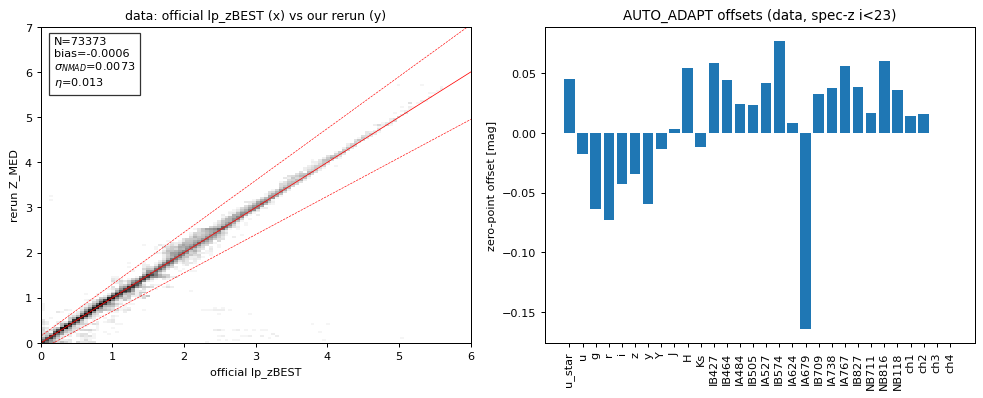

In [4]:
g = D[D.lp_type == 0]
off = np.load(f'{RUNS}/data_run_offsets.npy')
m = metrics(g.zp, g.lp_zBEST)
print(f"rerun Z_MED vs official lp_zBEST, all {len(g)} galaxies: bias {m['bias']:+.4f}  nmad {m['nmad']:.4f}  eta {m['eta']:.3f}")
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
zz_panel(ax[0], g.lp_zBEST, g.zp, title='data: official lp_zBEST (x) vs our rerun (y)', zmax=6)
ax[0].set_xlabel('official lp_zBEST'); ax[0].set_ylabel('rerun Z_MED')
ax[1].bar(range(len(off)), off); ax[1].set_xticks(range(len(off))); ax[1].set_xticklabels(list(BANDS), rotation=90)
ax[1].set_ylabel('zero-point offset [mag]'); ax[1].set_title('AUTO_ADAPT offsets (data, spec-z i<23)')
plt.tight_layout(); plt.show()

## 1. z_true vs z_phot

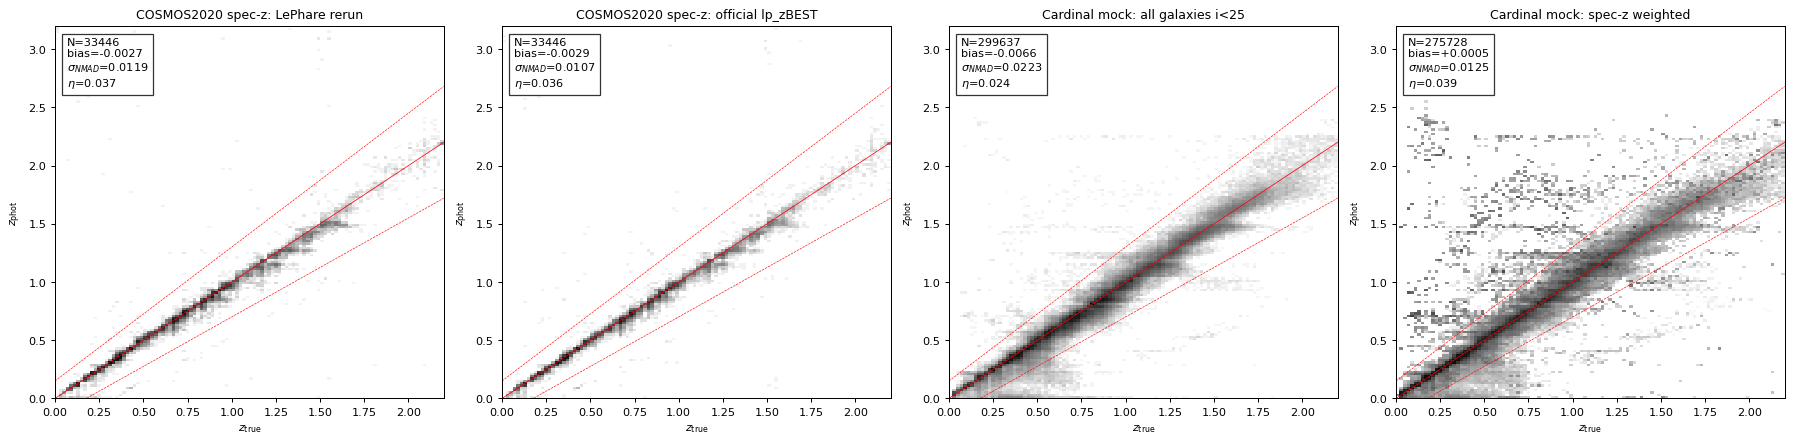

In [5]:
fig, axs = plt.subplots(1, 4, figsize=(20, 5))
zz_panel(axs[0], Ds.ztrue, Ds.zp, title='COSMOS2020 spec-z: LePhare rerun')
zz_panel(axs[1], Ds.ztrue, Ds.lp_zBEST, title='COSMOS2020 spec-z: official lp_zBEST')
zz_panel(axs[2], S.ztrue, S.zp, title='Cardinal mock: all galaxies i<25')
zz_panel(axs[3], S.ztrue, S.zp, w=S.w_spec, title='Cardinal mock: spec-z weighted')
plt.tight_layout(); plt.show()

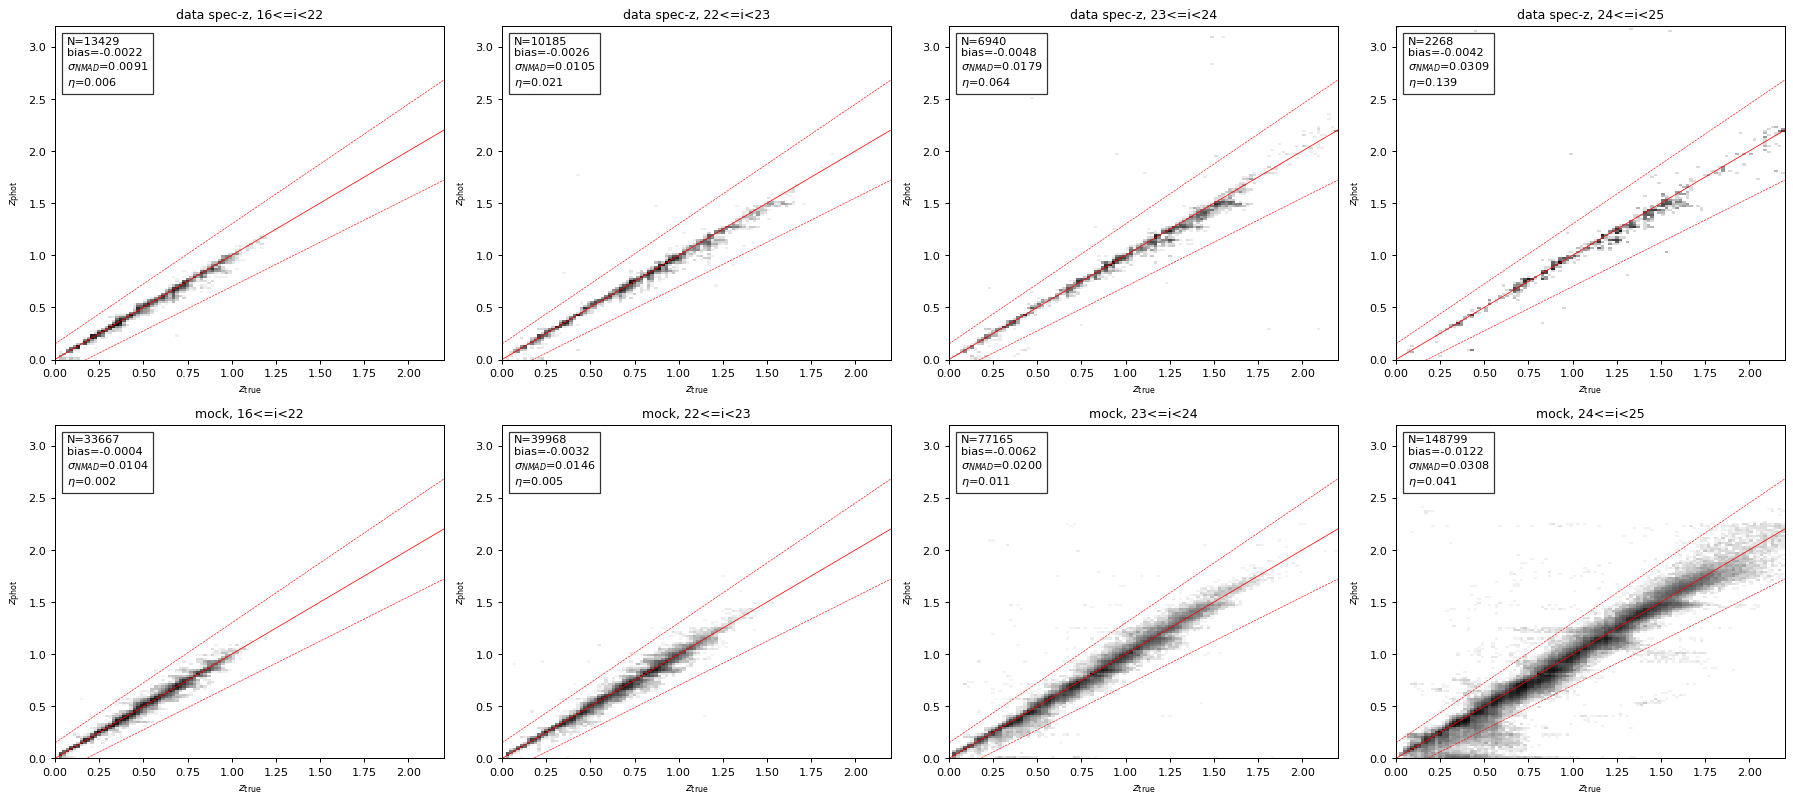

In [6]:
fig, axs = plt.subplots(2, 4, figsize=(20, 9))
for k, (lo, hi) in enumerate([(16, 22), (22, 23), (23, 24), (24, 25)]):
    d = Ds[(Ds.i_mag >= lo) & (Ds.i_mag < hi)]; s = S[(S.i_mag >= lo) & (S.i_mag < hi)]
    zz_panel(axs[0, k], d.ztrue, d.zp, title=f'data spec-z, {lo}<=i<{hi}')
    zz_panel(axs[1, k], s.ztrue, s.zp, title=f'mock, {lo}<=i<{hi}')
plt.tight_layout(); plt.show()

## 2. Bias, scatter and outlier rate on the (i-mag, z_true) grid
Within one (i, z) cell the spec-z selection matters much less, so data and mock can be compared cell by cell. The last column is mock − data. Cells need ≥20 objects.

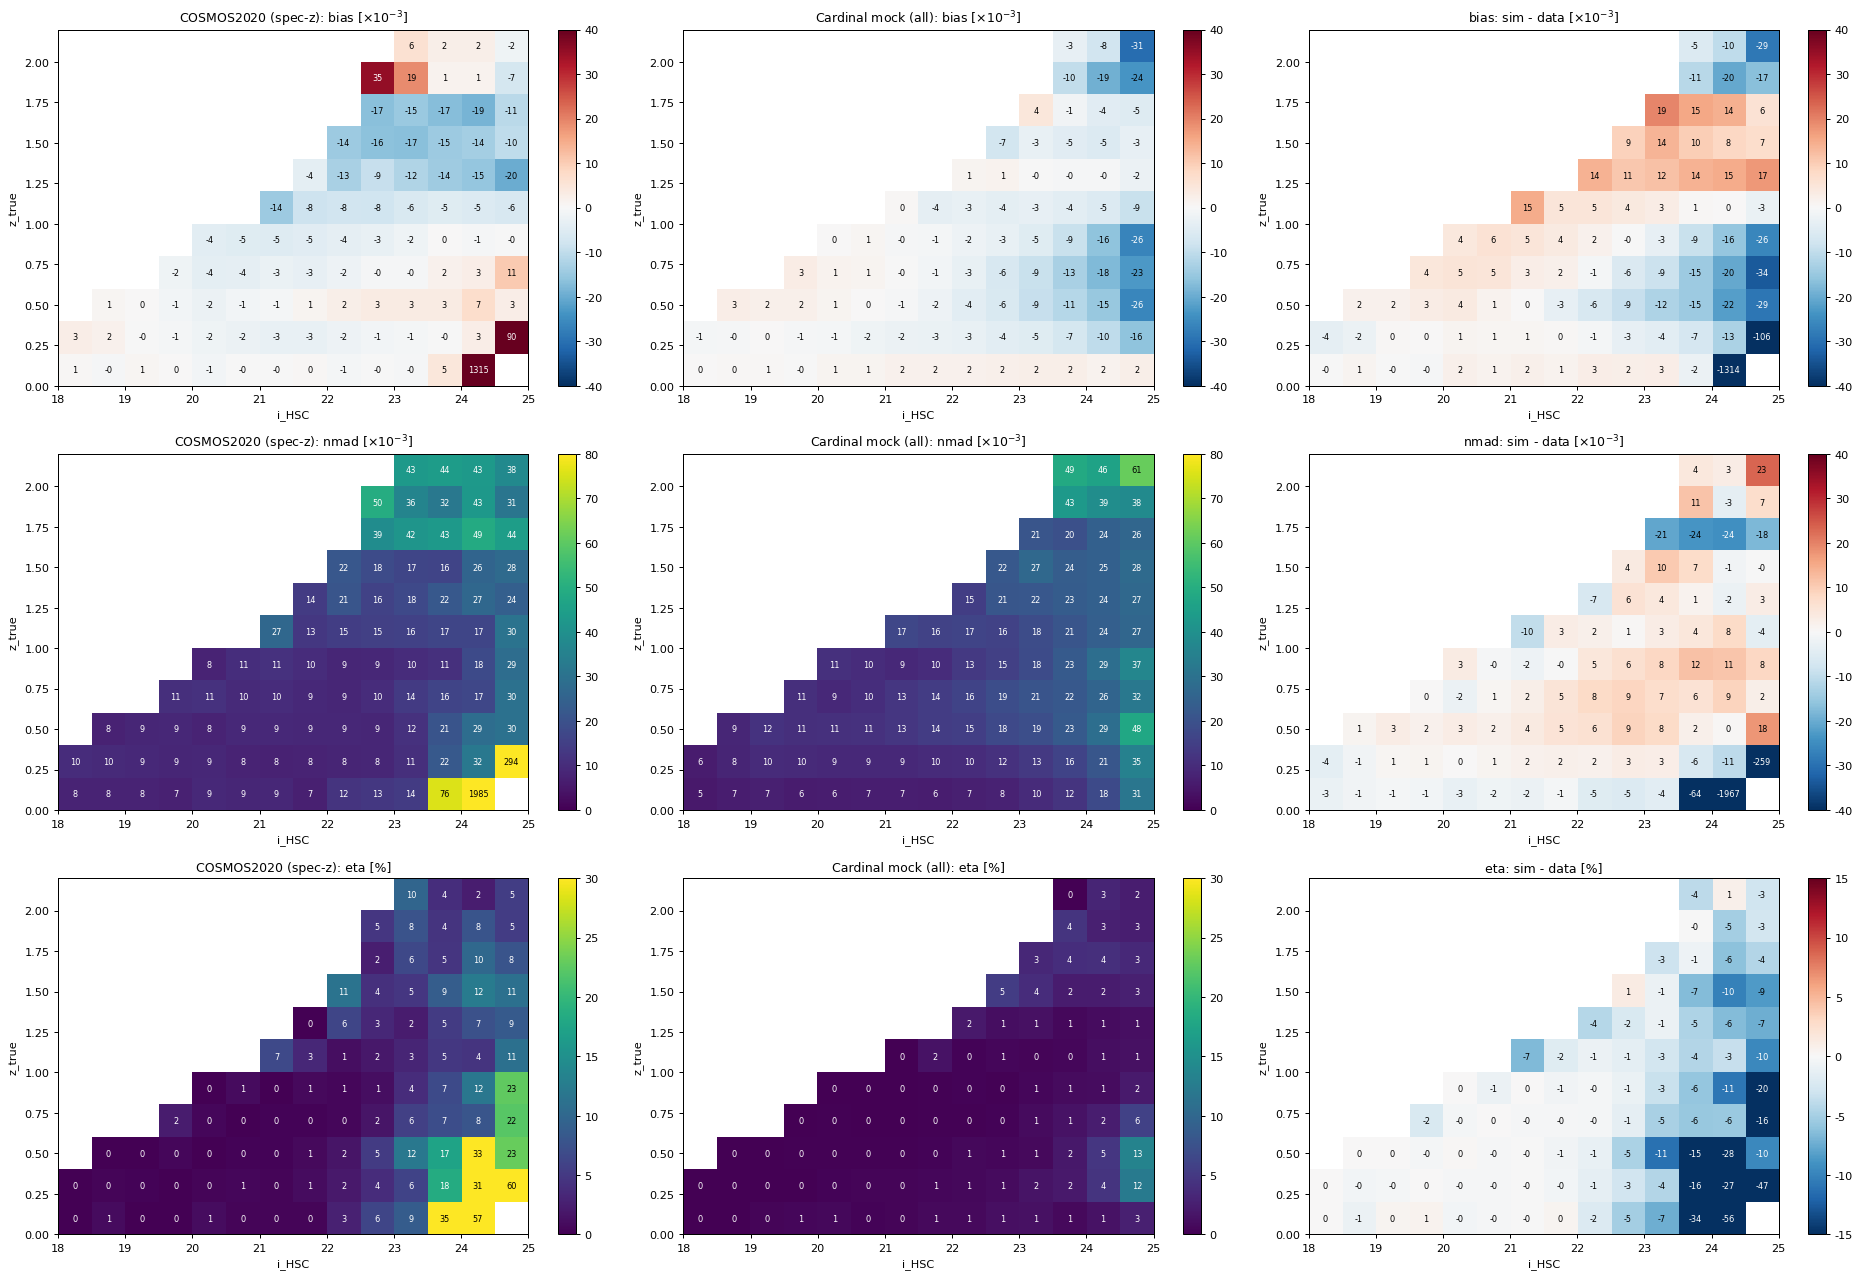

In [7]:
ib = np.arange(18, 25.01, 0.5); zb = np.arange(0, ZMAX + 0.001, 0.2)
G = {'data': grid2d(Ds, 'i_mag', ib, 'ztrue', zb), 'sim': grid2d(S, 'i_mag', ib, 'ztrue', zb)}
fig = grid_figure(G, ['data', 'sim'], ib, zb, 'i_HSC', 'z_true'); plt.show()

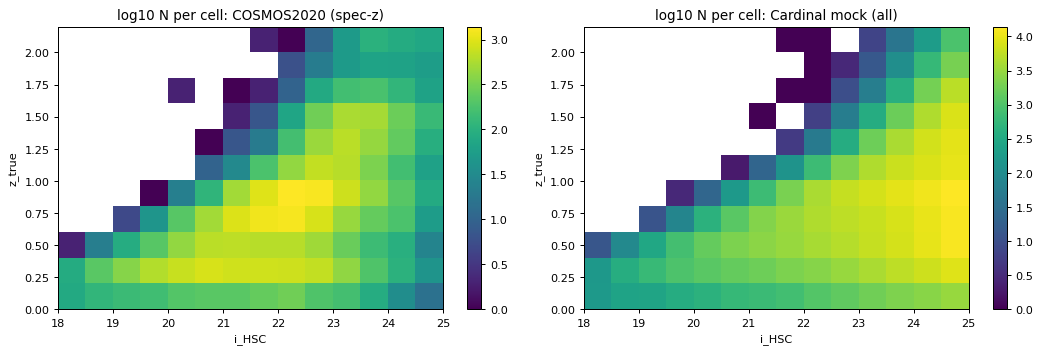

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for ax, n in zip(axs, ['data', 'sim']):
    im = ax.imshow(np.log10(G[n]['N']), origin='lower', extent=[ib[0], ib[-1], zb[0], zb[-1]], aspect='auto'); plt.colorbar(im, ax=ax)
    ax.set_title(f'log10 N per cell: {LABELS[n]}'); ax.set_xlabel('i_HSC'); ax.set_ylabel('z_true')
plt.tight_layout(); plt.show()

### Same grid in (i-mag, z_phot)
Binning in photo-z, the quantity available in practice, and measuring the scatter of z_true around it.

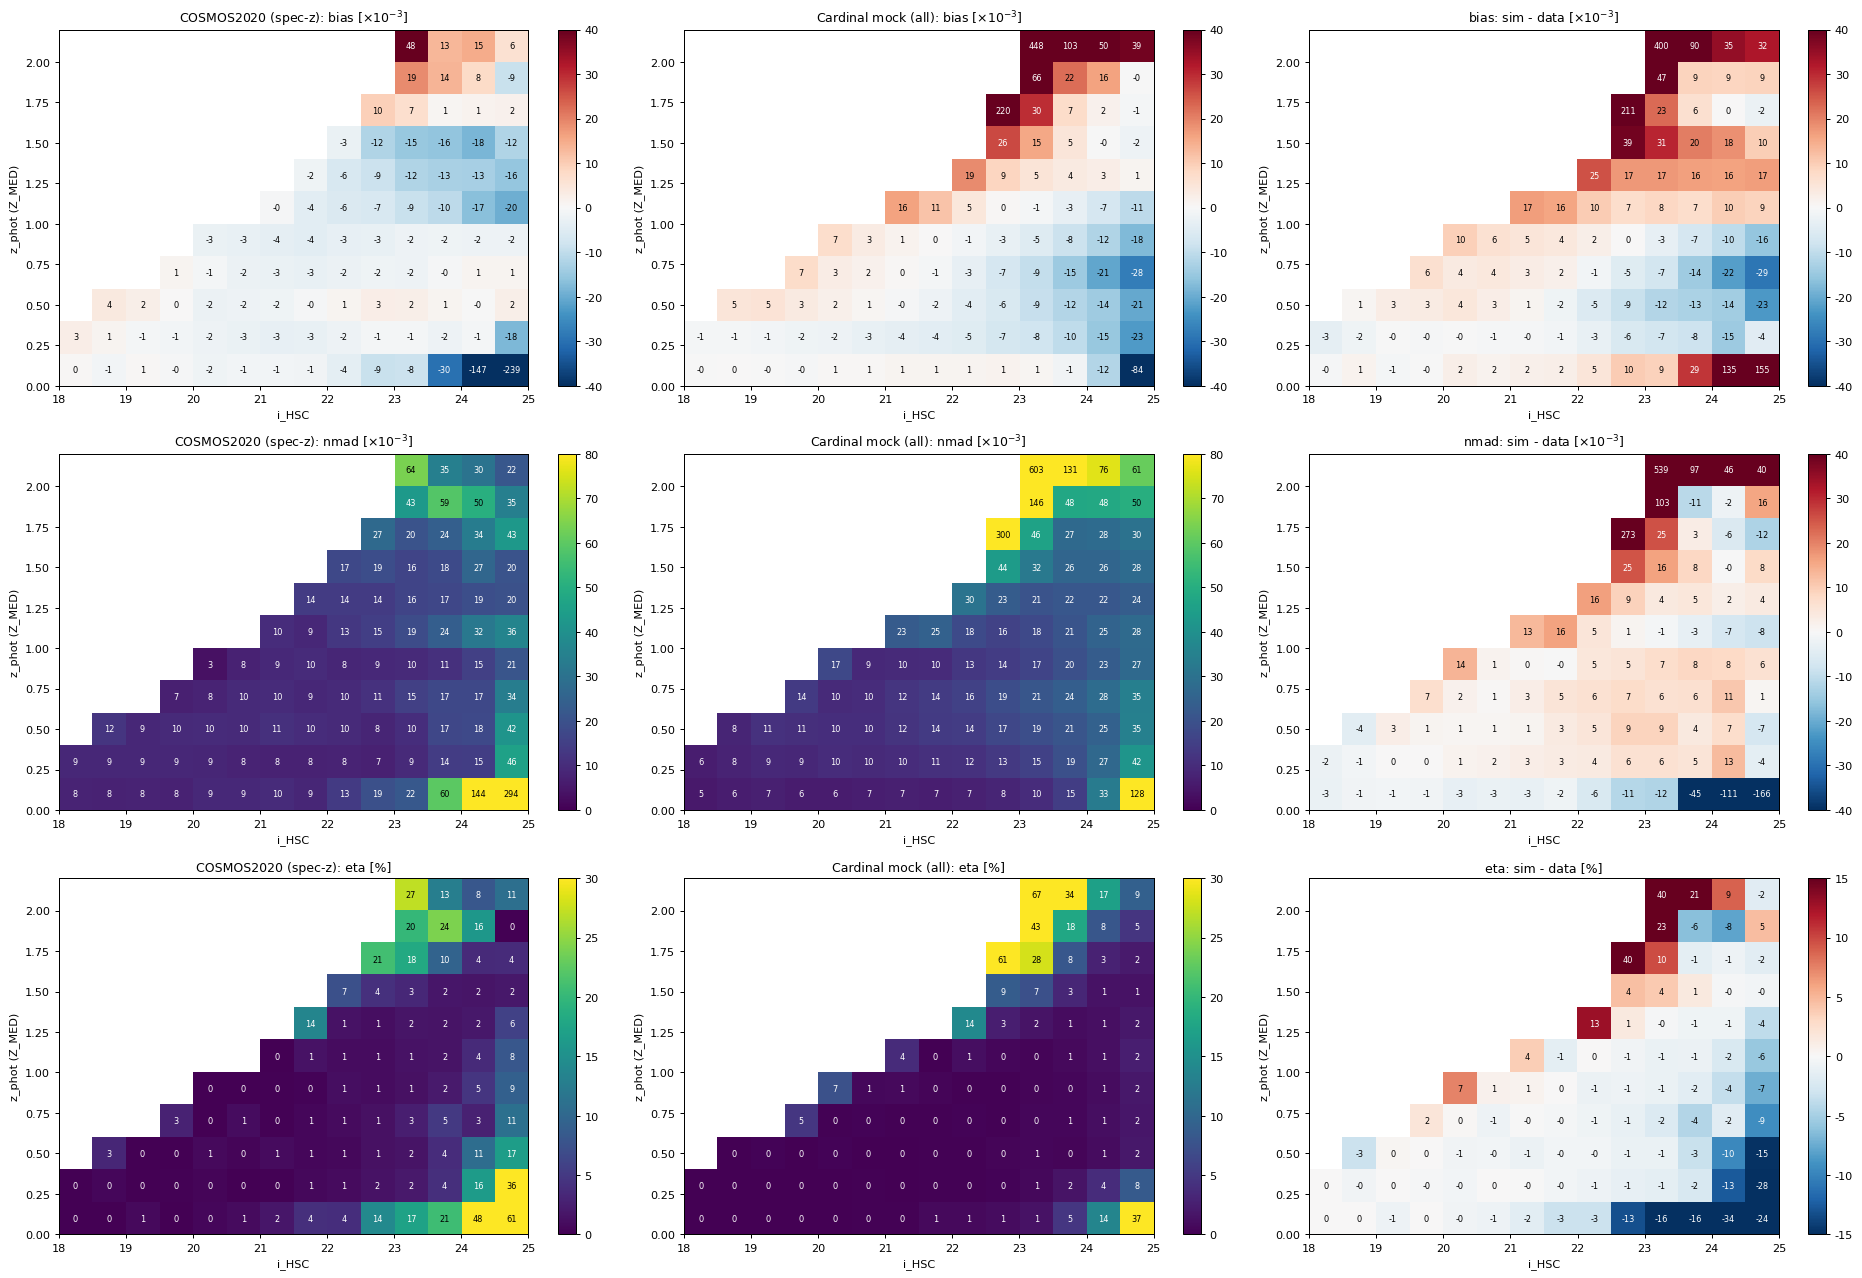

In [9]:
Gp = {'data': grid2d(Ds, 'i_mag', ib, 'zp', zb), 'sim': grid2d(S, 'i_mag', ib, 'zp', zb)}
fig = grid_figure(Gp, ['data', 'sim'], ib, zb, 'i_HSC', 'z_phot (Z_MED)'); plt.show()

### 1-D: metrics vs i-mag and vs z_true

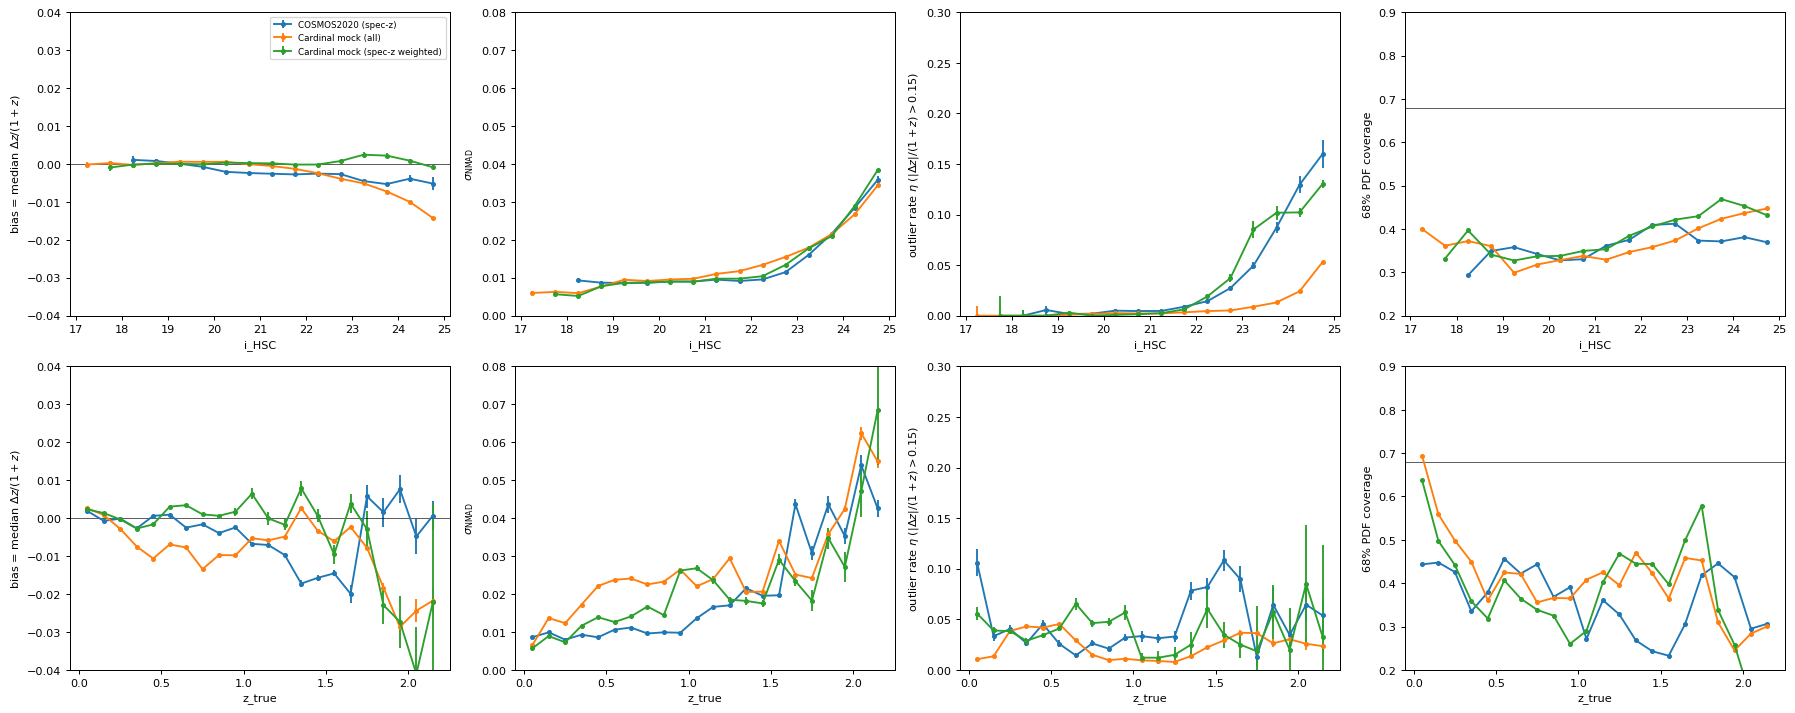

In [10]:
fig, axs = plt.subplots(2, 4, figsize=(20, 8))
samples = {'data': (Ds, None), 'sim': (S, None), 'sim_w': (S, 'w_spec')}
for r, (col, bins, lab) in enumerate([('i_mag', np.arange(17, 25.01, 0.5), 'i_HSC'), ('ztrue', np.arange(0, ZMAX + 0.01, 0.1), 'z_true')]):
    for name, (df, w) in samples.items():
        t = binned(df, col, bins, w)
        for k, m in enumerate(['bias', 'nmad', 'eta', 'cov68']):
            axs[r, k].errorbar(t.x, t[m], yerr=t.get(f'{m}_err'), fmt='o-', ms=3, color=COLORS[name], label=LABELS[name])
            axs[r, k].set_xlabel(lab); axs[r, k].set_ylabel(MLAB[m]); axs[r, k].set_ylim(*MLIM[m])
    axs[r, 0].axhline(0, c='k', lw=0.5); axs[r, 3].axhline(0.68, c='k', lw=0.5)
axs[0, 0].legend(fontsize=7); plt.tight_layout(); plt.show()

## 3. Bias, scatter and outlier rate vs colour, in i-magnitude brackets
Data (spec-z truth) vs mock (true z). Error bars are approximate statistical errors (bias: 1.25σ/√N, σ_NMAD: σ/√2N, η: binomial). Points need ≥15 objects.

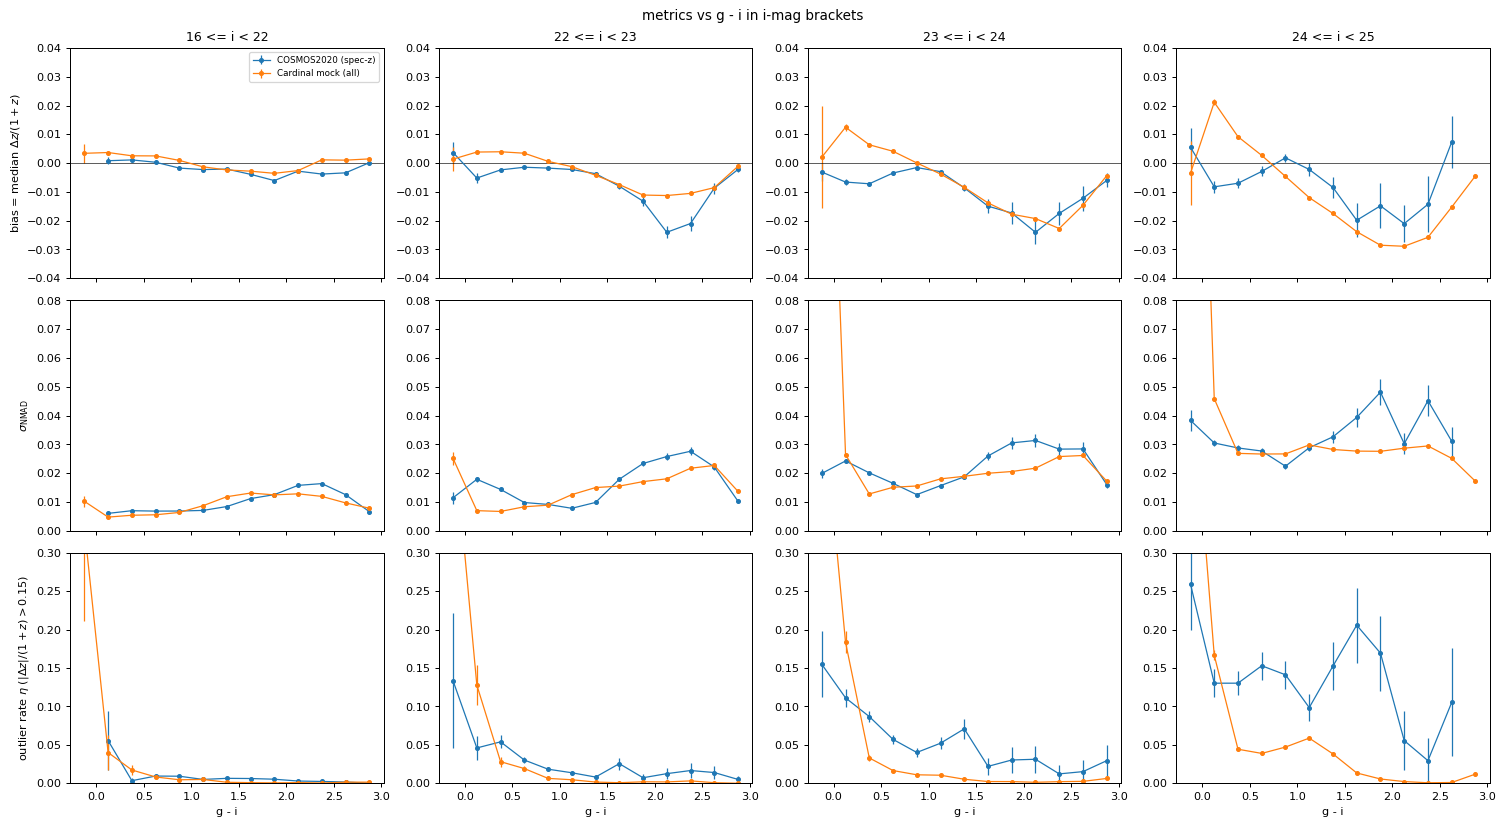

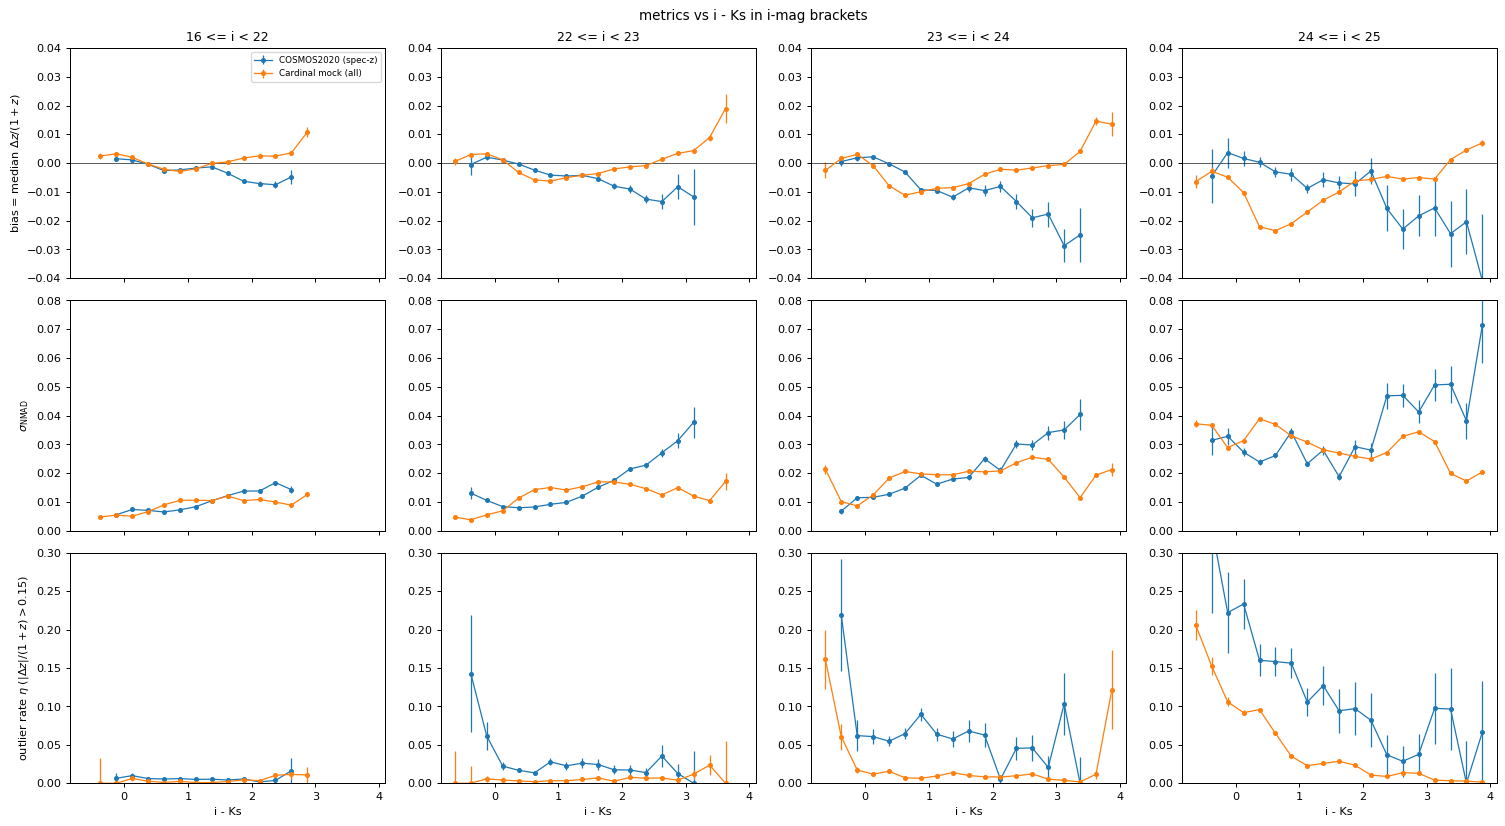

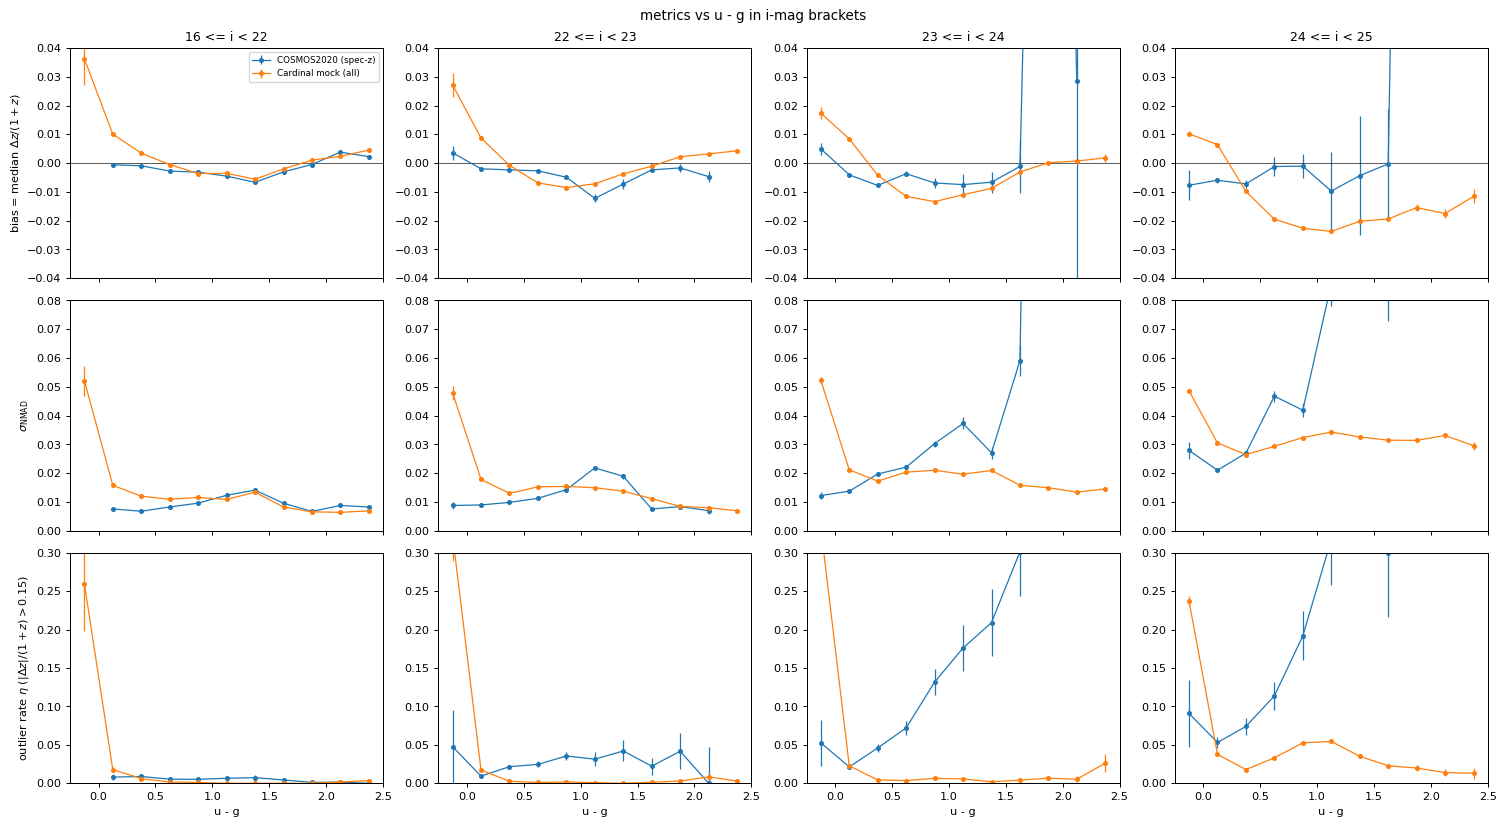

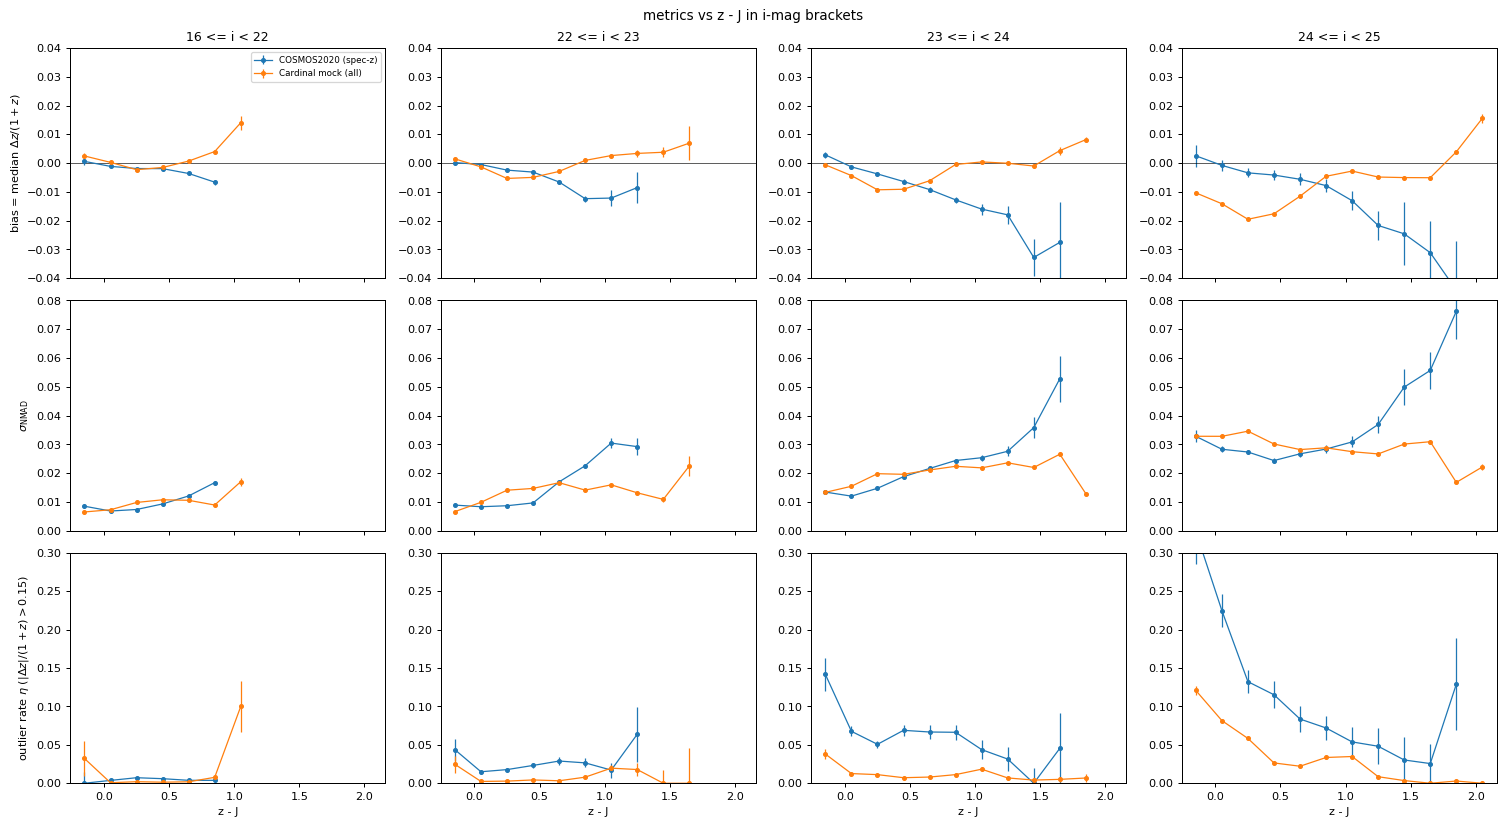

In [11]:
brackets = [(16, 22), (22, 23), (23, 24), (24, 25)]
samples = {'data': (Ds, None), 'sim': (S, None)}
for col, cb, lab in [('g_i', np.arange(-0.25, 3.01, 0.25), 'g - i'), ('i_Ks', np.arange(-0.75, 4.01, 0.25), 'i - Ks'),
                     ('u_g', np.arange(-0.25, 2.51, 0.25), 'u - g'), ('z_J', np.arange(-0.25, 2.51, 0.2), 'z - J')]:
    fig = curves_figure(samples, col, cb, brackets, 'i_mag', 'i', lab, suptitle=f'metrics vs {lab} in i-mag brackets'); plt.show()

### Same, with the mock weighted to the spec-z sample's colour–magnitude distribution
Inside a colour bin of a magnitude bracket, the weighting only redistributes within the remaining dimension (the other colour), so the curves change little. Large changes would indicate the spec-z selection picks a particular sub-population.

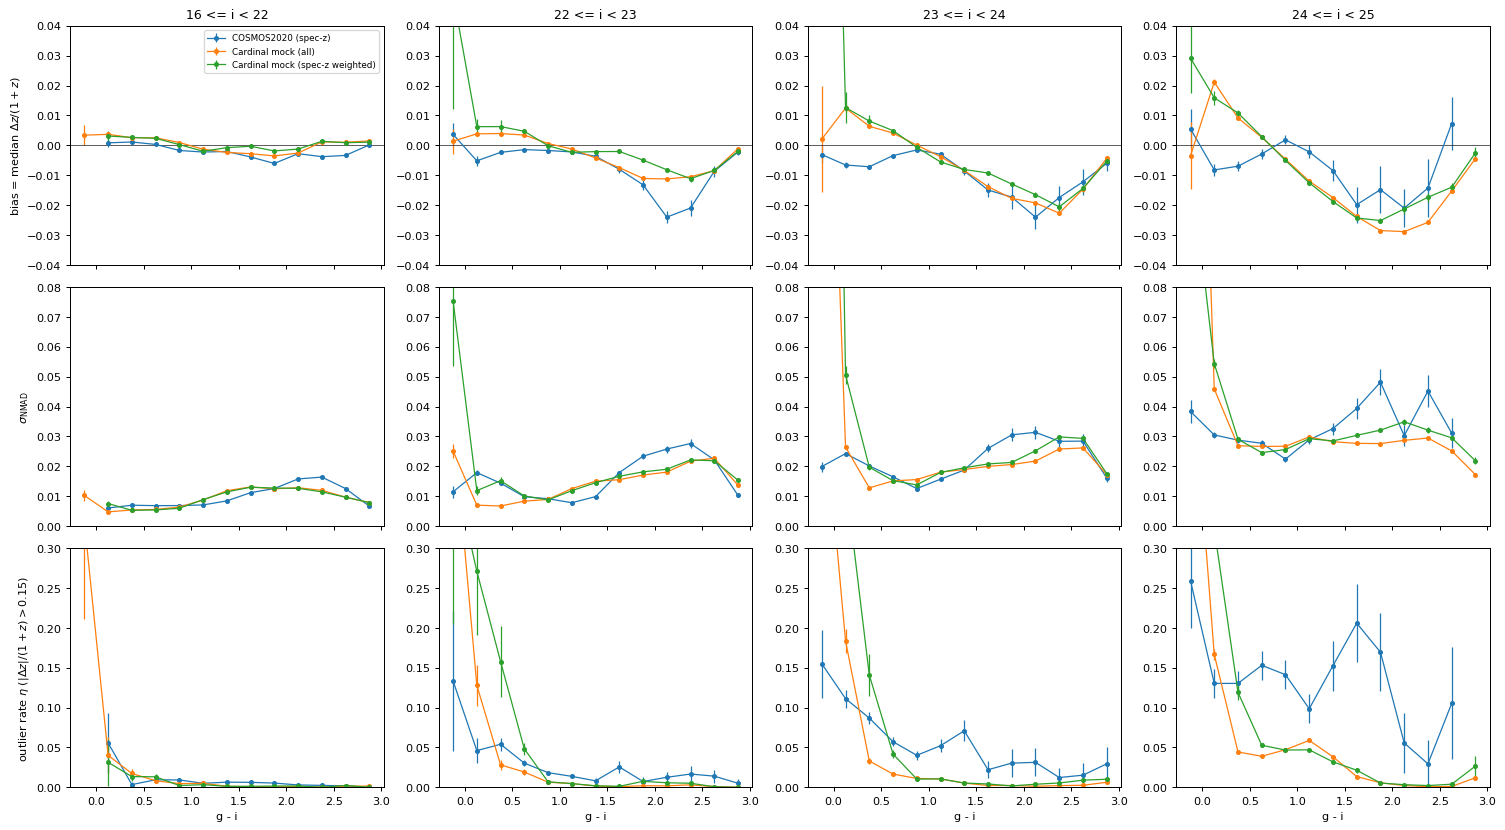

In [12]:
samples_w = {'data': (Ds, None), 'sim': (S, None), 'sim_w': (S, 'w_spec')}
fig = curves_figure(samples_w, 'g_i', np.arange(-0.25, 3.01, 0.25), brackets, 'i_mag', 'i', 'g - i'); plt.show()

## 4. Metrics vs colour at fixed magnitude, in z_true brackets
For each i-magnitude bracket, metrics vs colour in four true-redshift brackets. Bracketing on z_true for the mock and spec-z for the data shows how much of the colour dependence is redshift dependence.

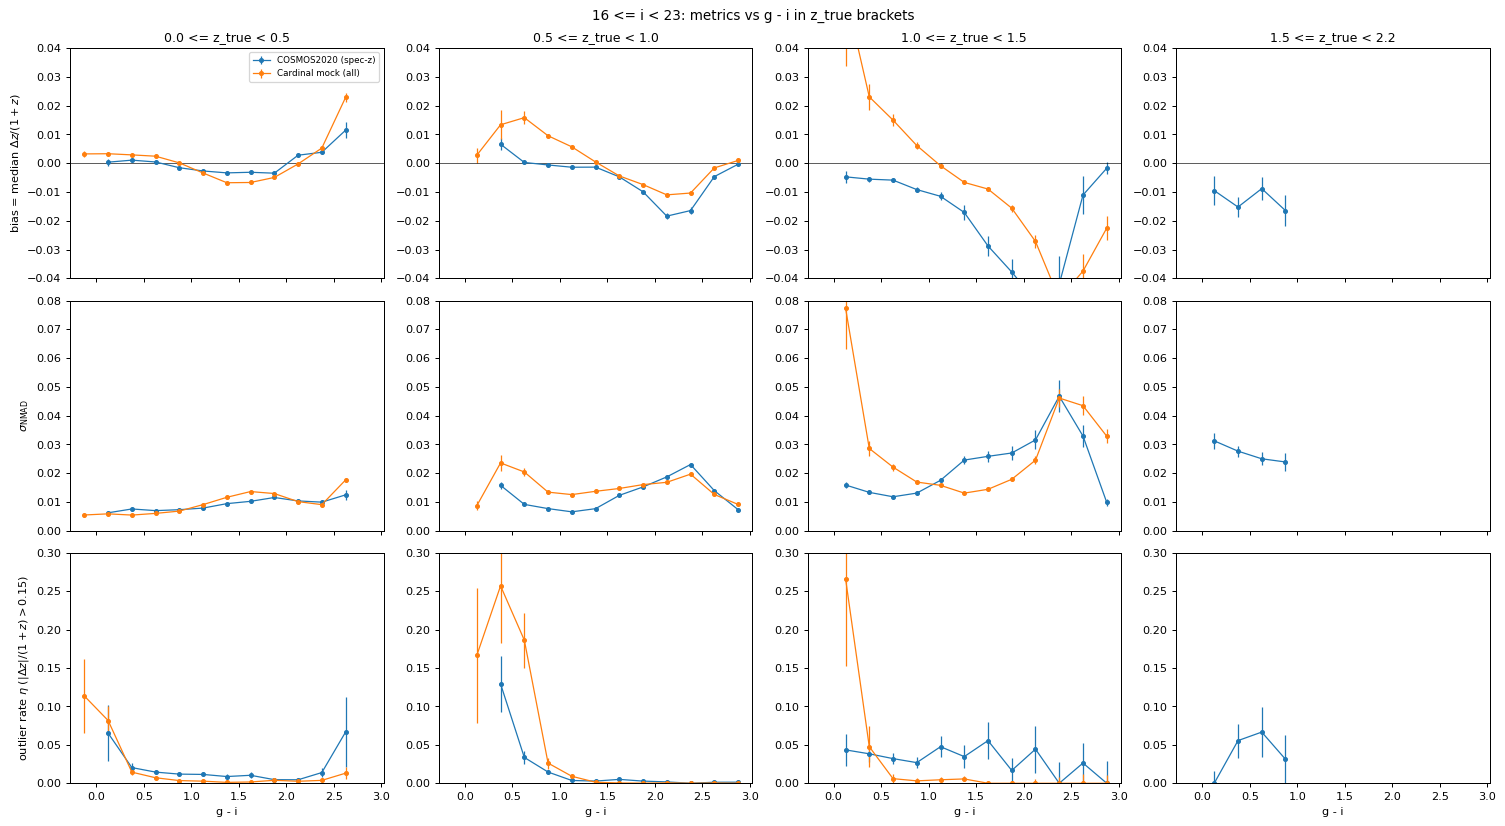

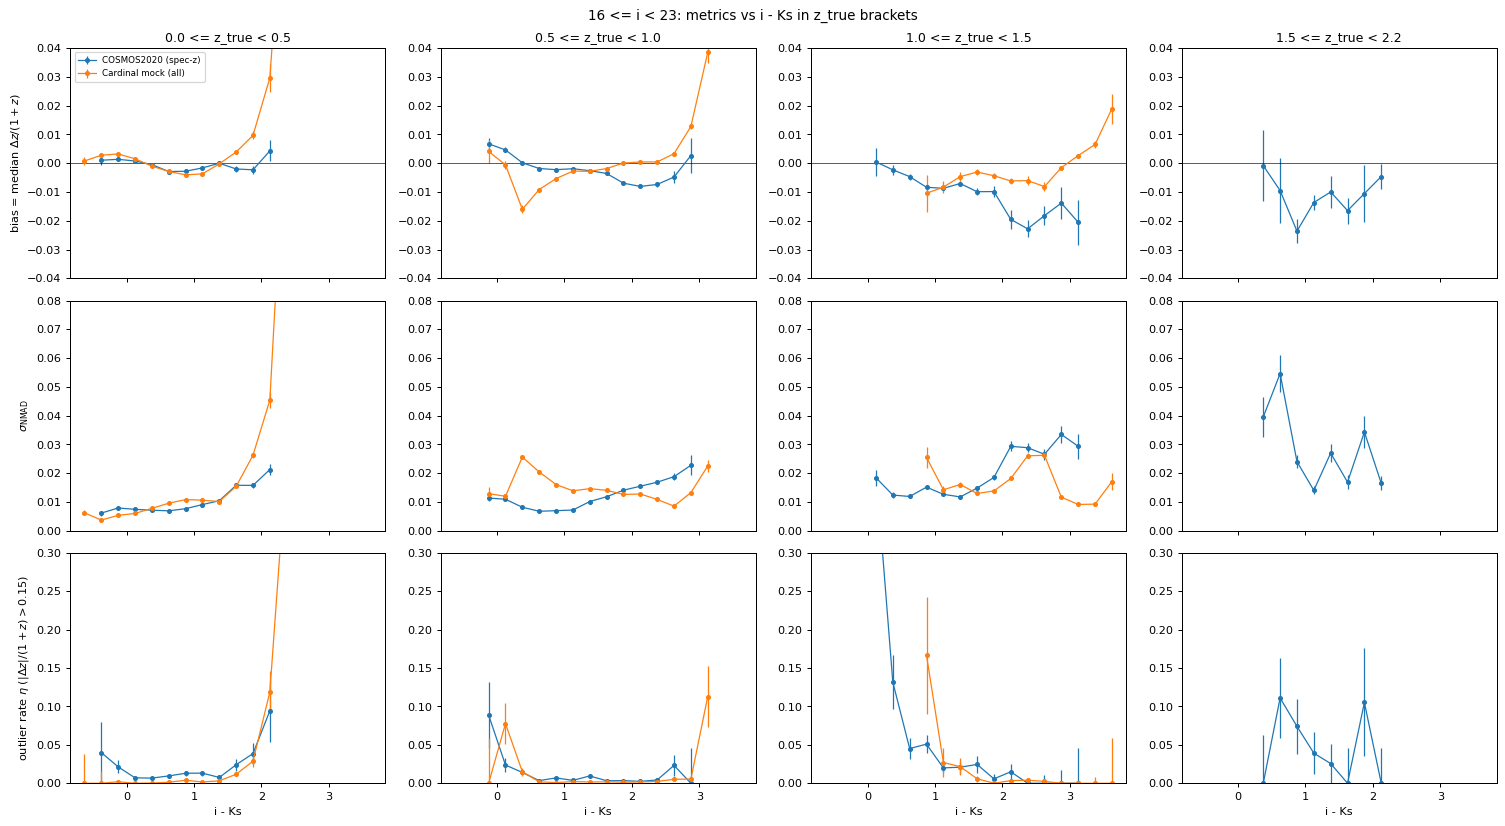

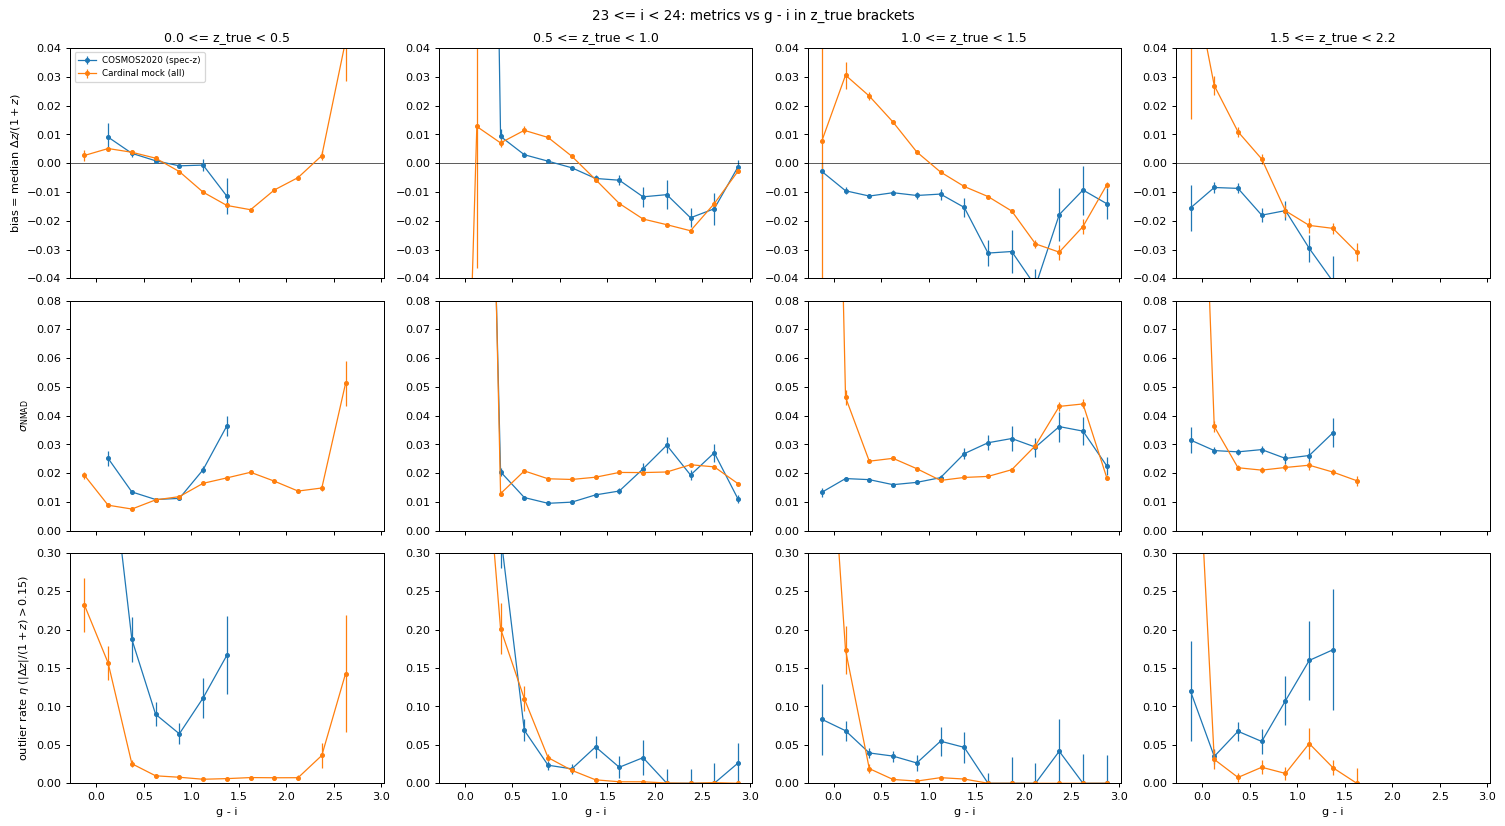

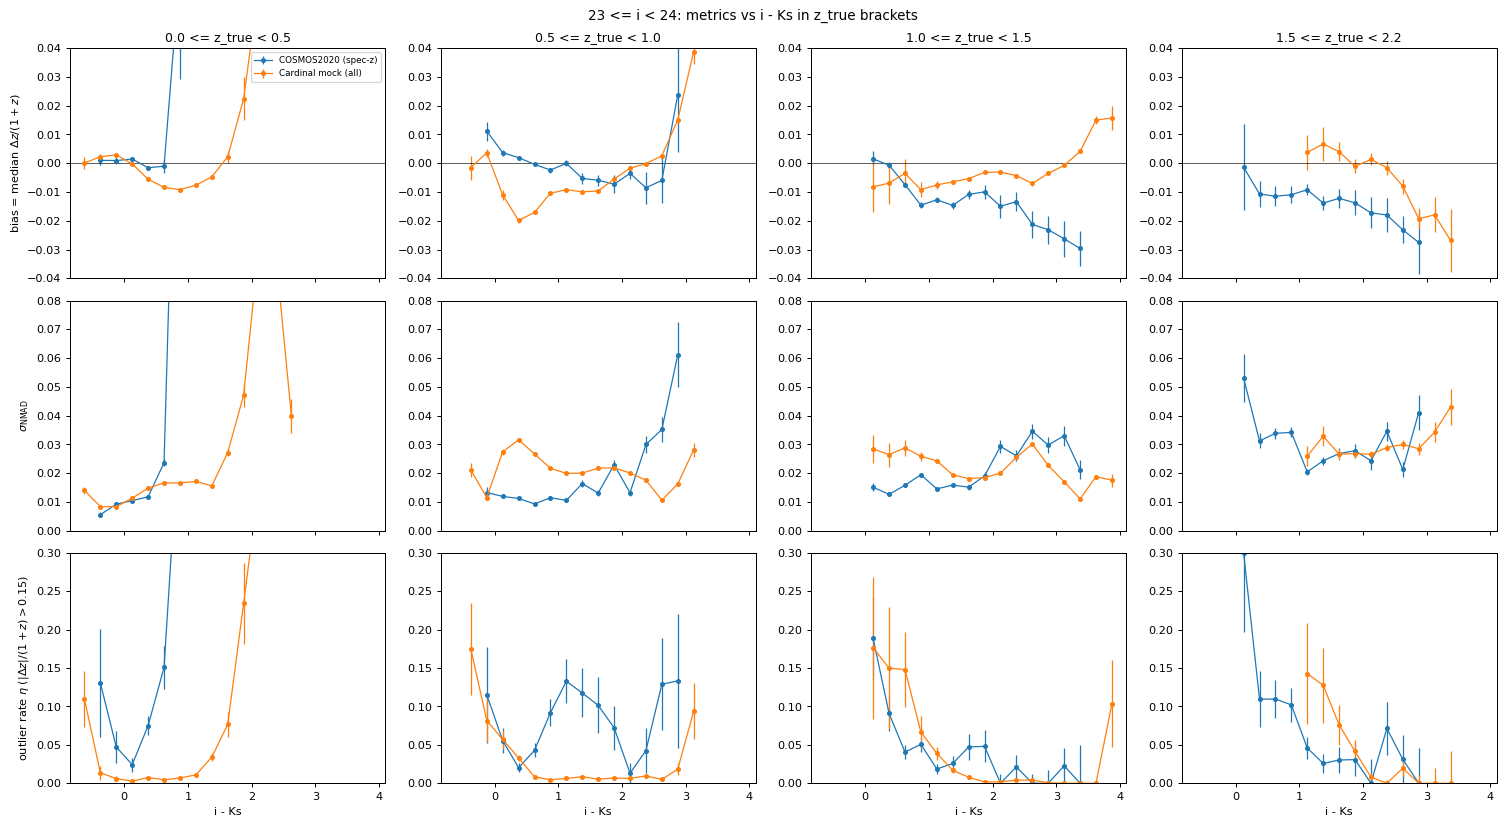

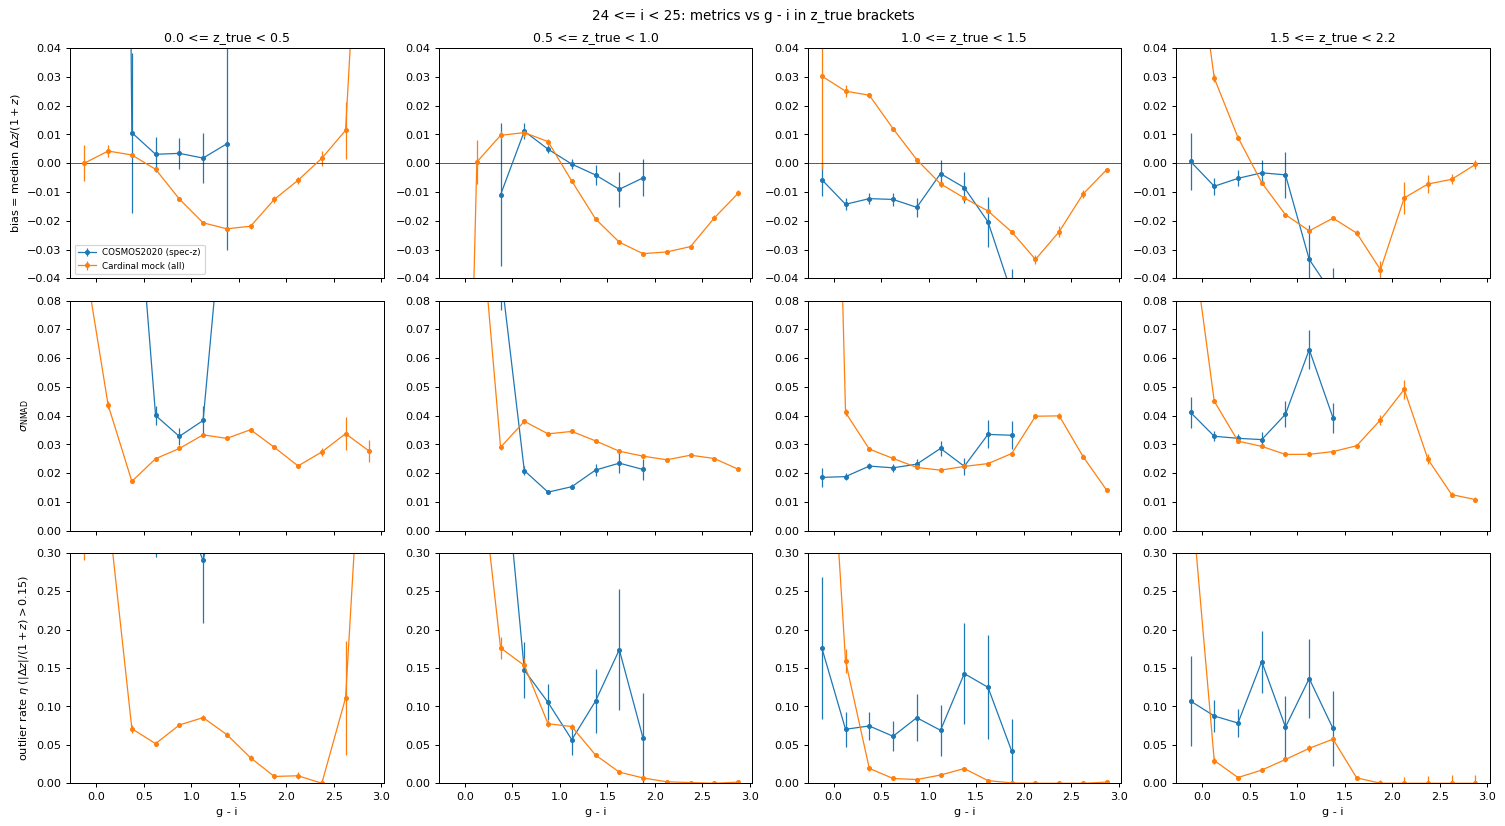

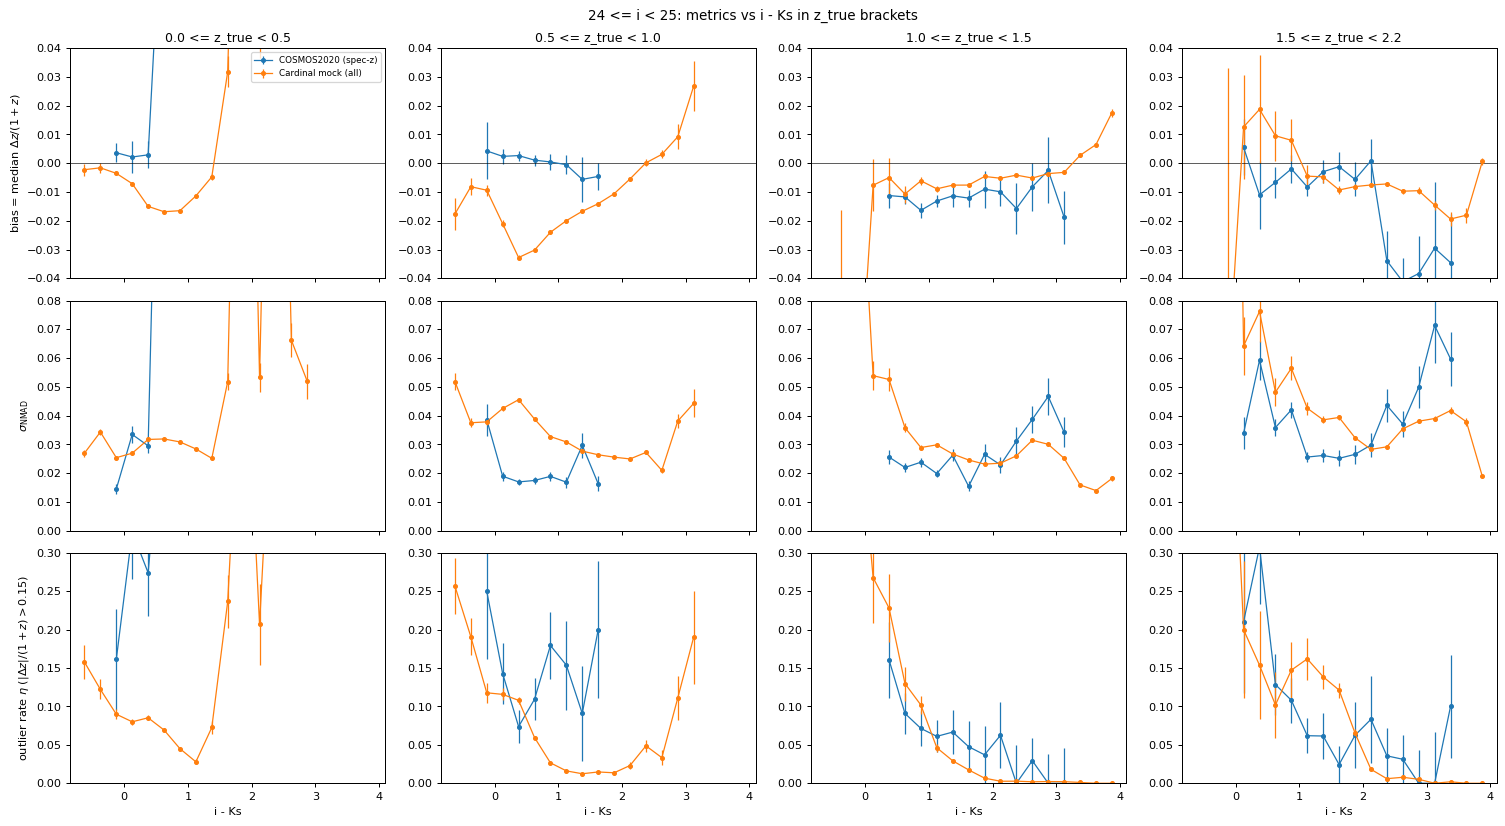

In [13]:
zbr = [(0.0, 0.5), (0.5, 1.0), (1.0, 1.5), (1.5, ZMAX)]
for (lo, hi) in [(16, 23), (23, 24), (24, 25)]:
    for col, cb, lab in [('g_i', np.arange(-0.25, 3.01, 0.25), 'g - i'), ('i_Ks', np.arange(-0.75, 4.01, 0.25), 'i - Ks')]:
        sel = lambda g, lo=lo, hi=hi: (g.i_mag >= lo) & (g.i_mag < hi)
        fig = curves_figure({'data': (Ds, None), 'sim': (S, None)}, col, cb, zbr, 'ztrue', 'z_true', lab, extra_sel=sel,
                            suptitle=f'{lo} <= i < {hi}: metrics vs {lab} in z_true brackets'); plt.show()

### Same, bracketing on z_phot (what an analysis can actually select on)

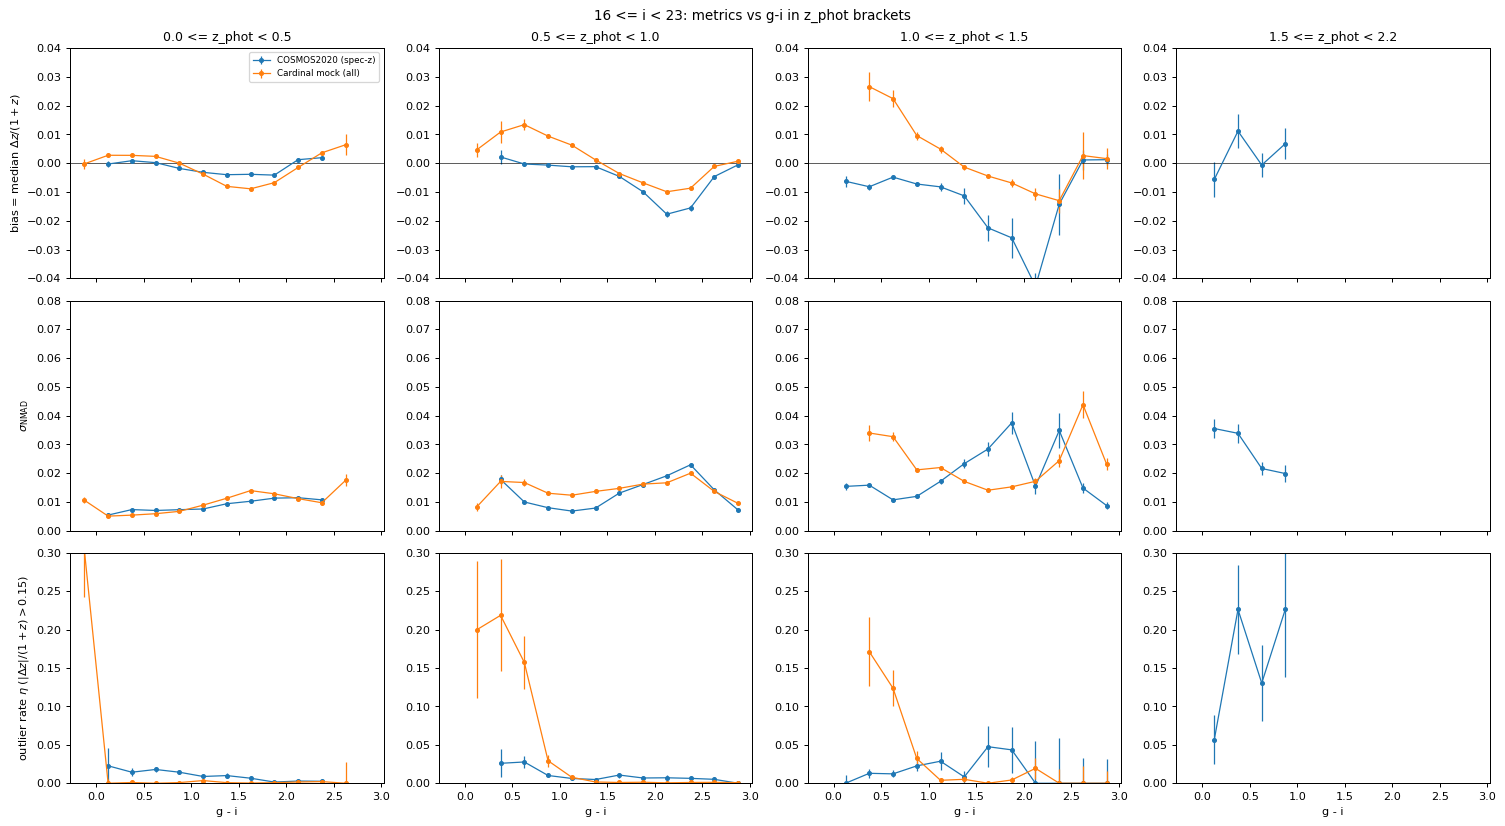

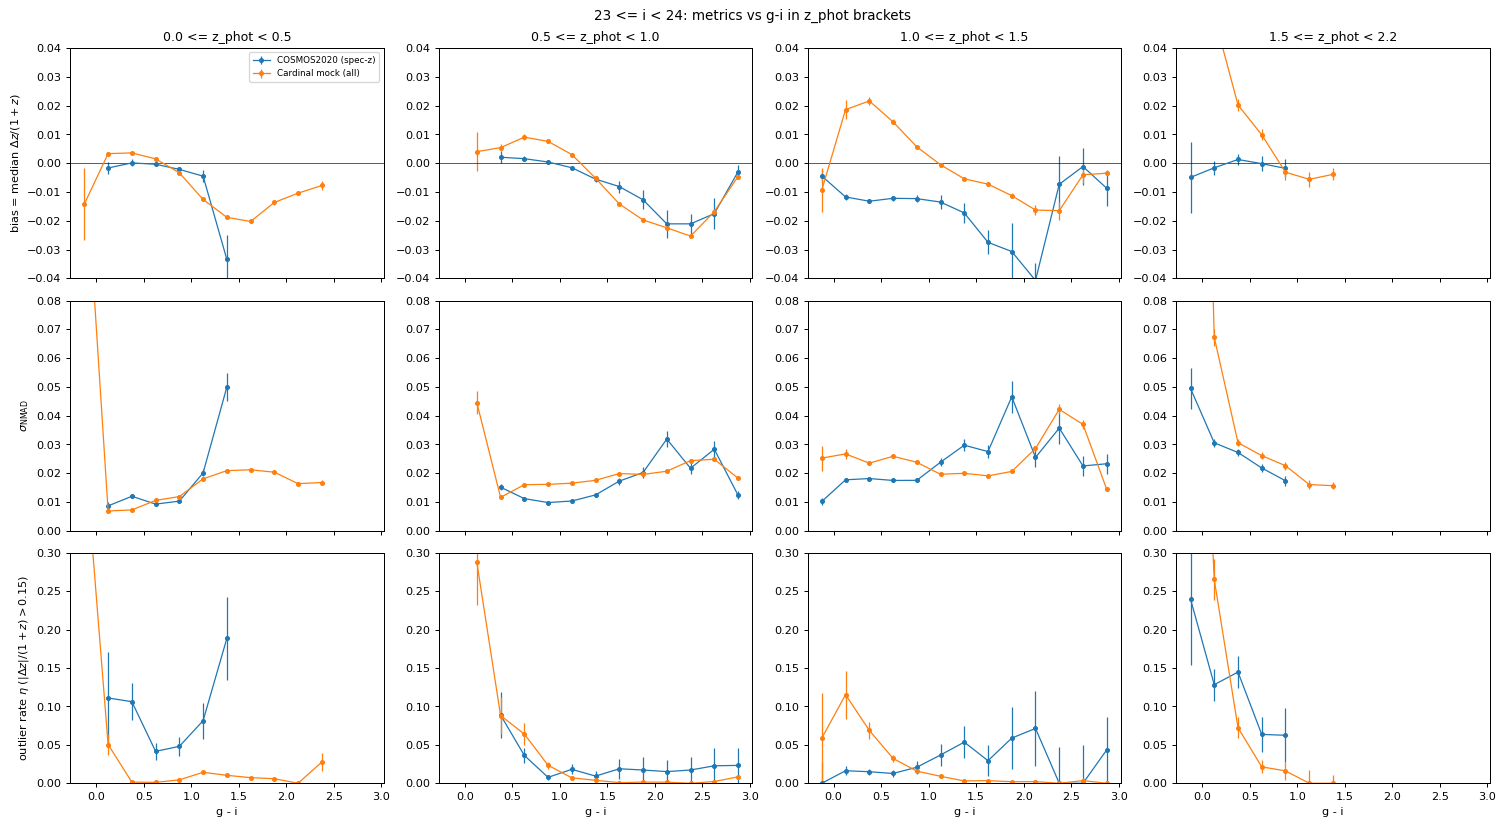

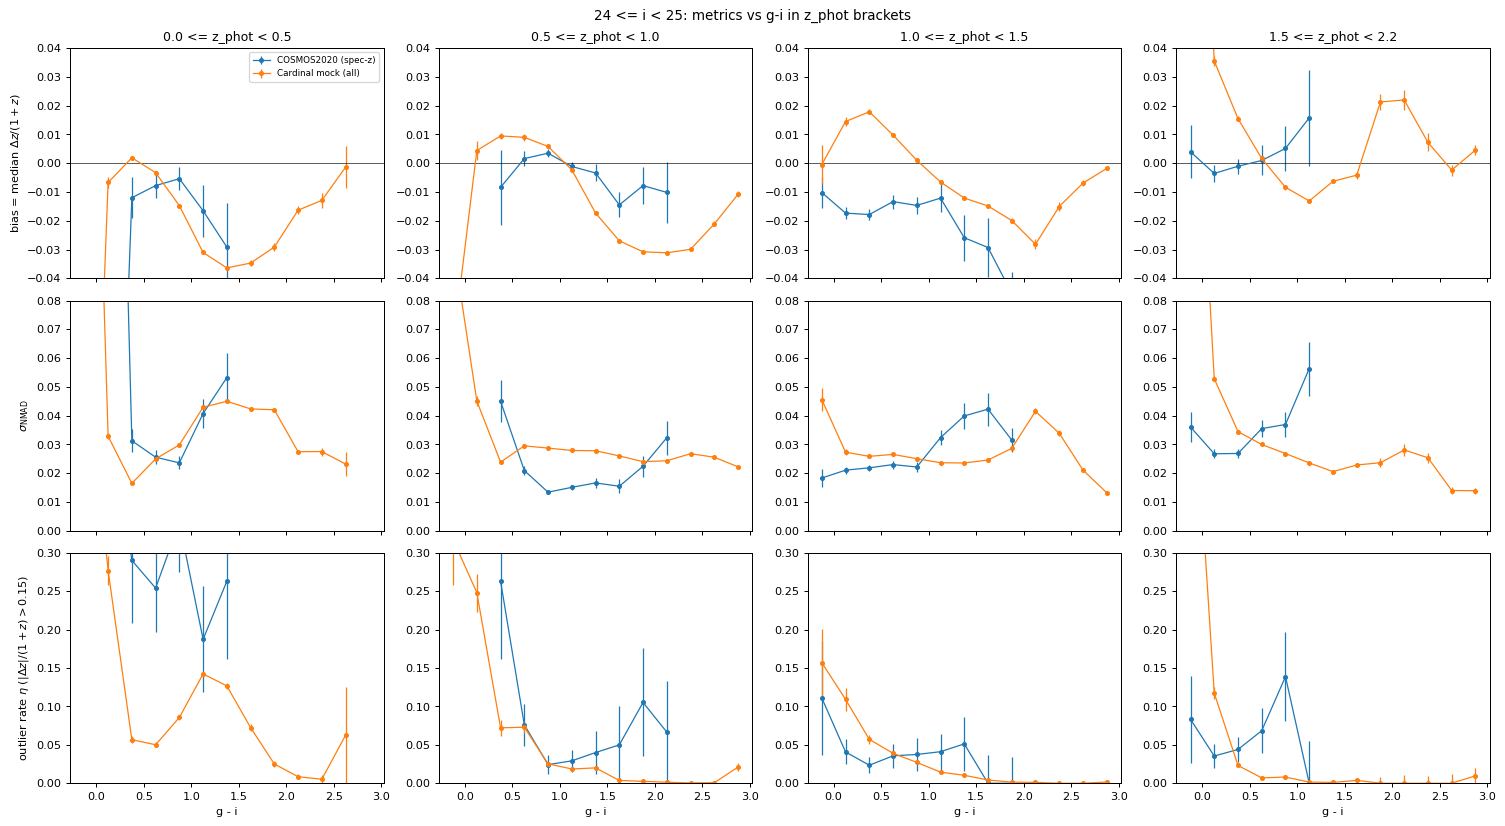

In [14]:
for (lo, hi) in [(16, 23), (23, 24), (24, 25)]:
    sel = lambda g, lo=lo, hi=hi: (g.i_mag >= lo) & (g.i_mag < hi)
    fig = curves_figure({'data': (Ds, None), 'sim': (S, None)}, 'g_i', np.arange(-0.25, 3.01, 0.25), zbr, 'zp', 'z_phot', 'g - i',
                        extra_sel=sel, suptitle=f'{lo} <= i < {hi}: metrics vs g-i in z_phot brackets'); plt.show()

## 5. 2-D colour–colour maps (g−i vs i−Ks) of the metrics, per i bracket

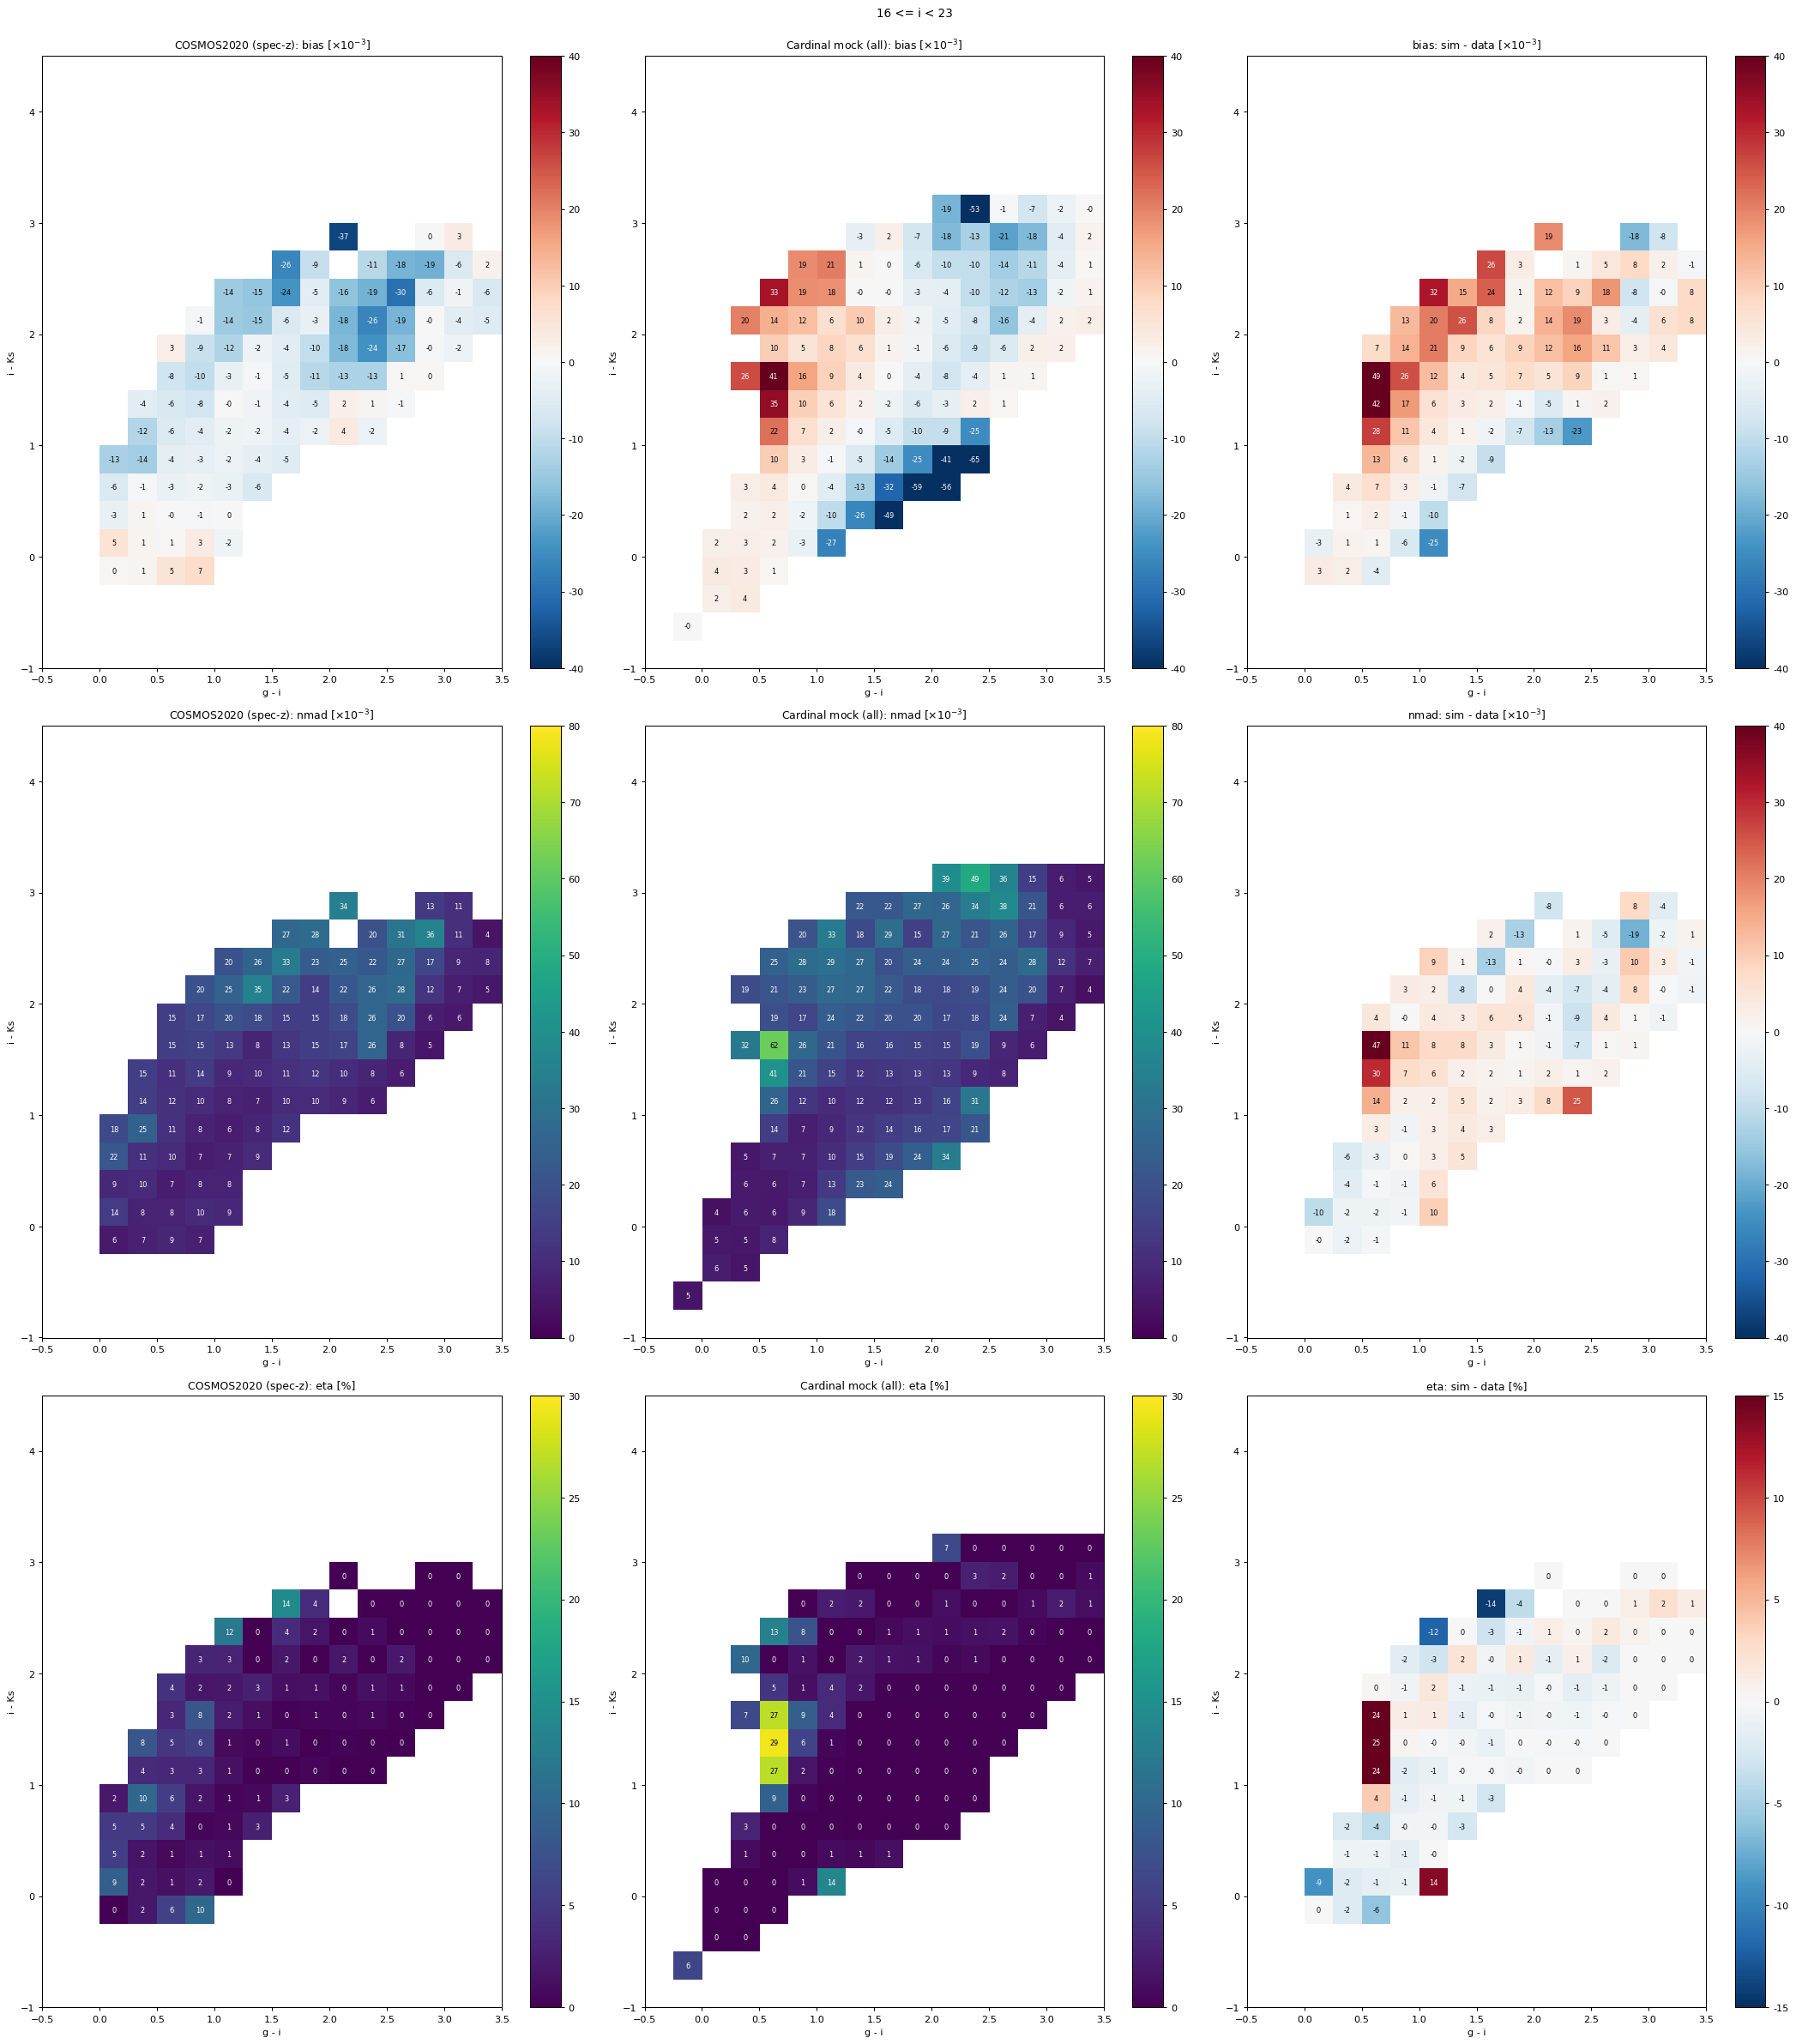

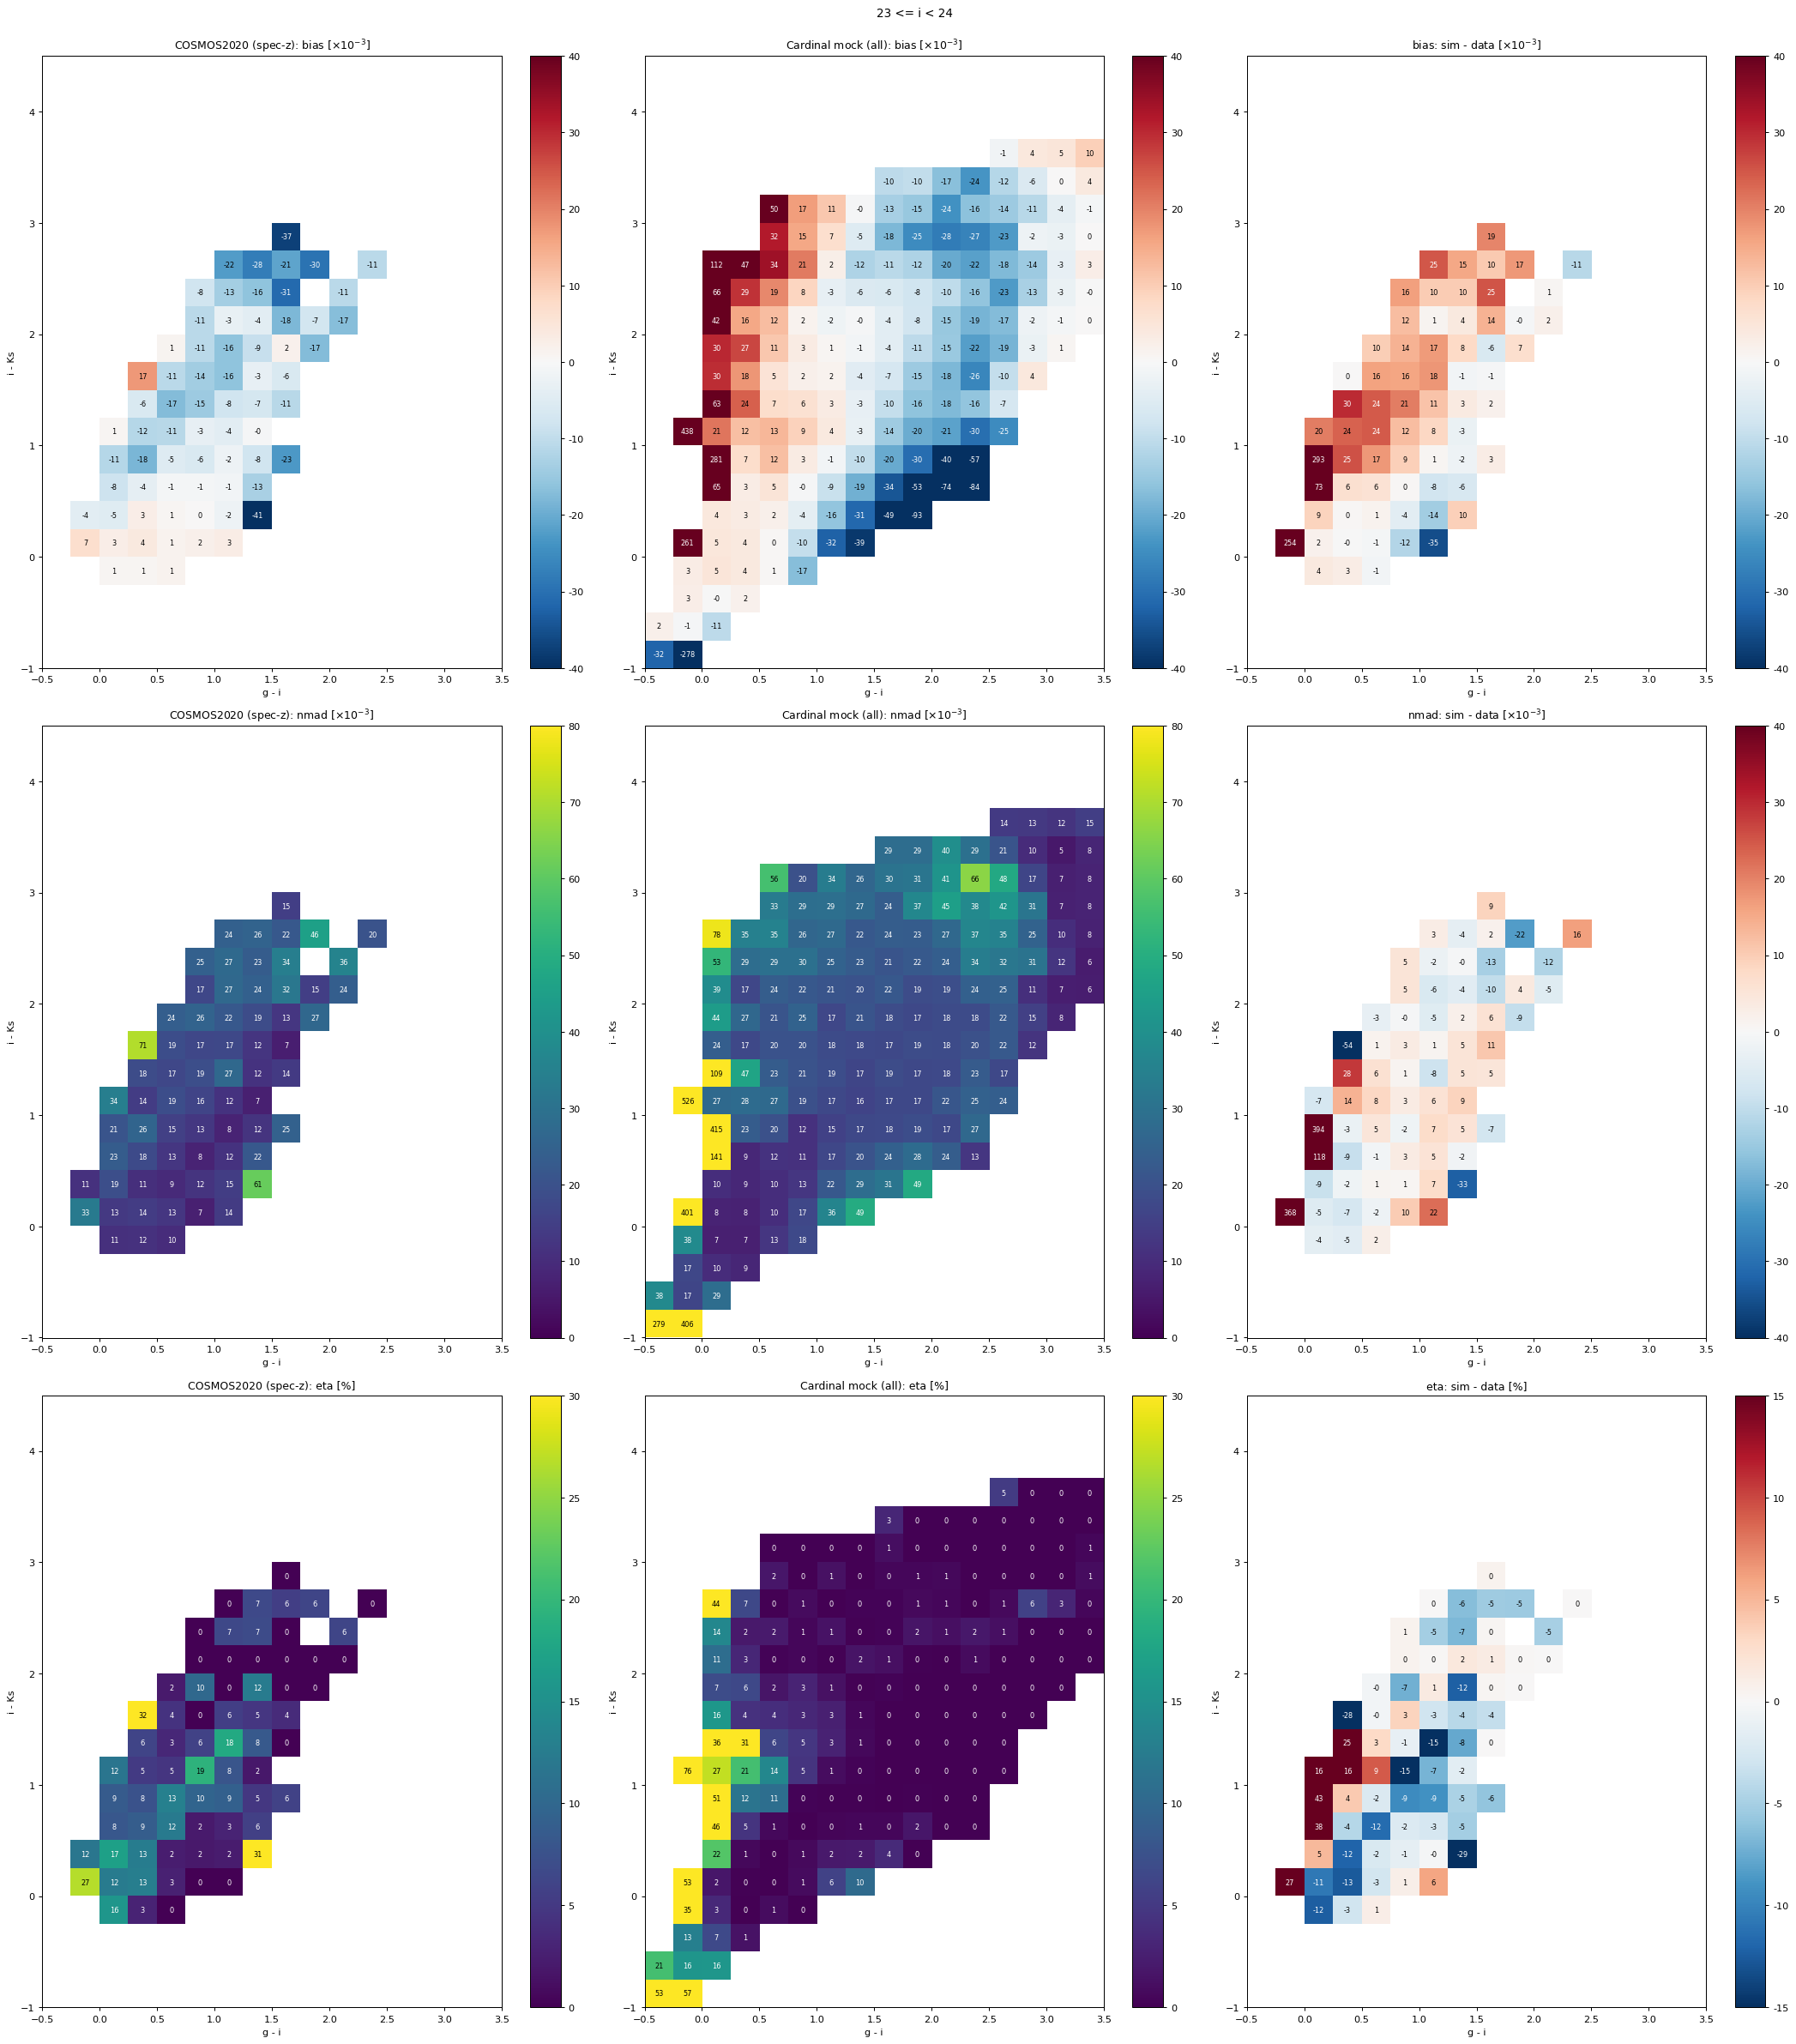

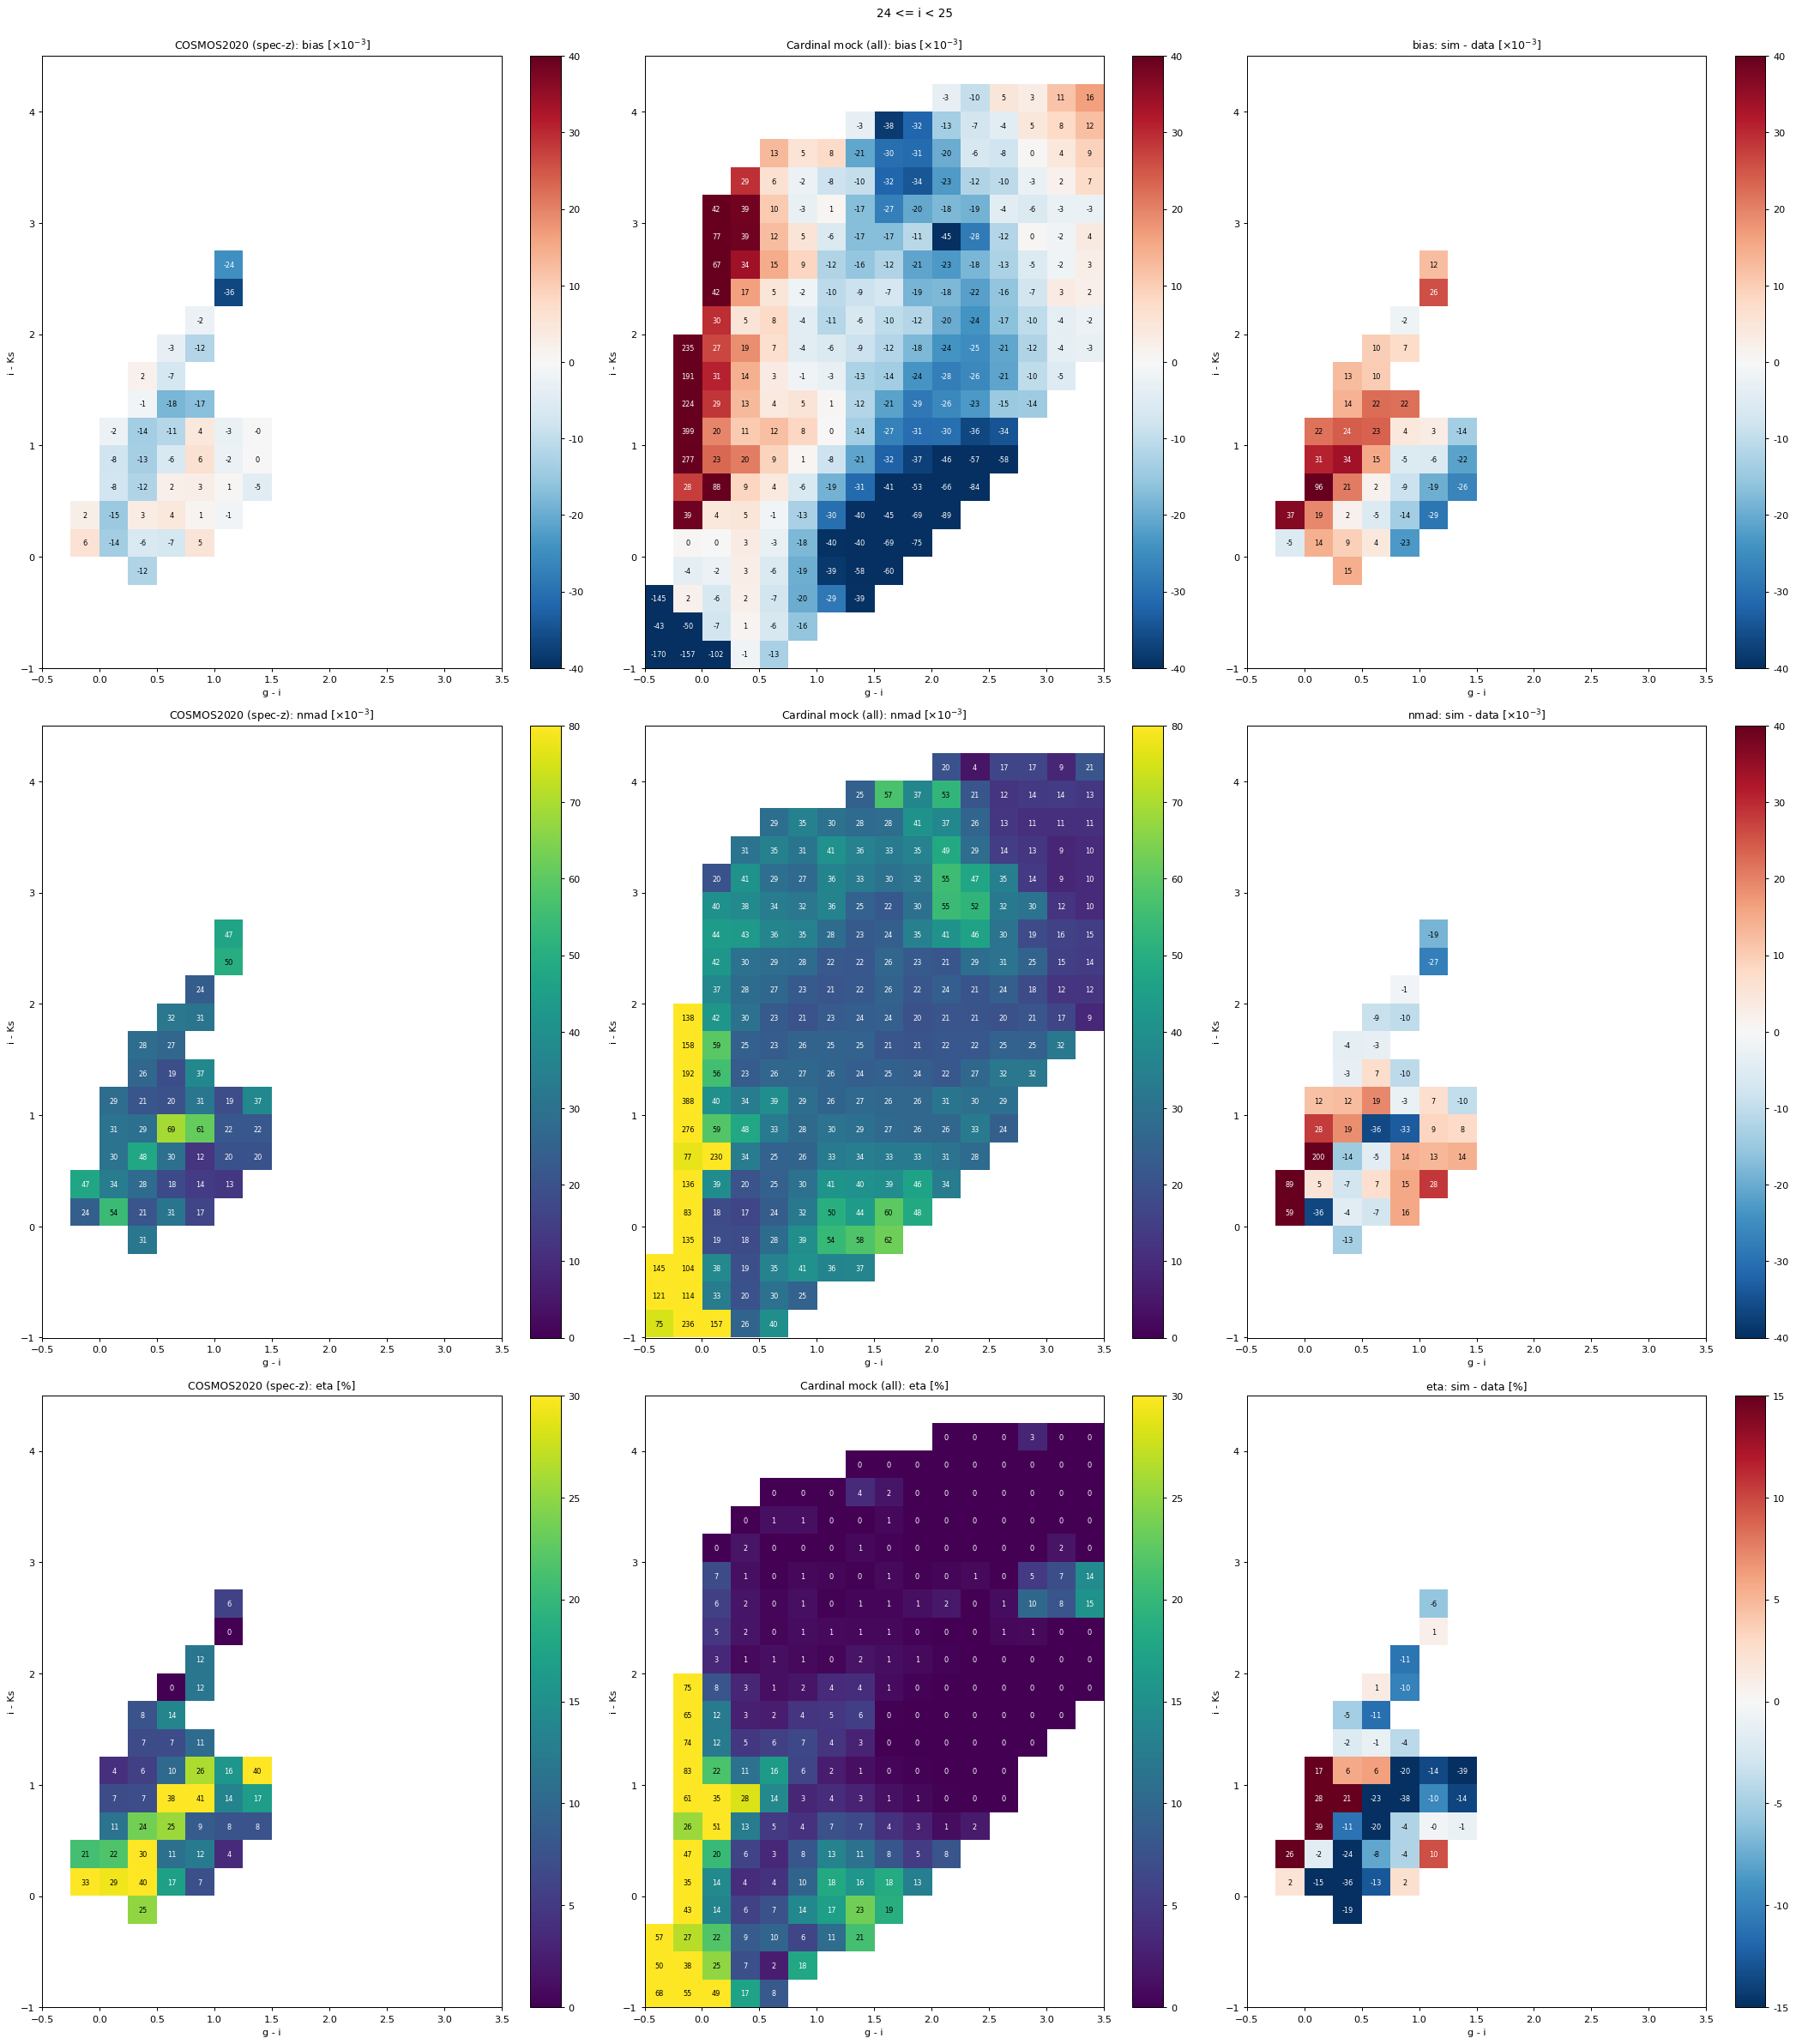

In [15]:
gb = np.arange(-0.5, 3.51, 0.25); kb = np.arange(-1.0, 4.51, 0.25)
for (lo, hi) in [(16, 23), (23, 24), (24, 25)]:
    d = Ds[(Ds.i_mag >= lo) & (Ds.i_mag < hi)]; s = S[(S.i_mag >= lo) & (S.i_mag < hi)]
    Gc = {'data': grid2d(d, 'g_i', gb, 'i_Ks', kb, nmin=15), 'sim': grid2d(s, 'g_i', gb, 'i_Ks', kb, nmin=15)}
    fig = grid_figure(Gc, ['data', 'sim'], gb, kb, 'g - i', 'i - Ks'); fig.suptitle(f'{lo} <= i < {hi}', y=1.01); plt.show()

## 6. PDF calibration: PIT and 68% interval width

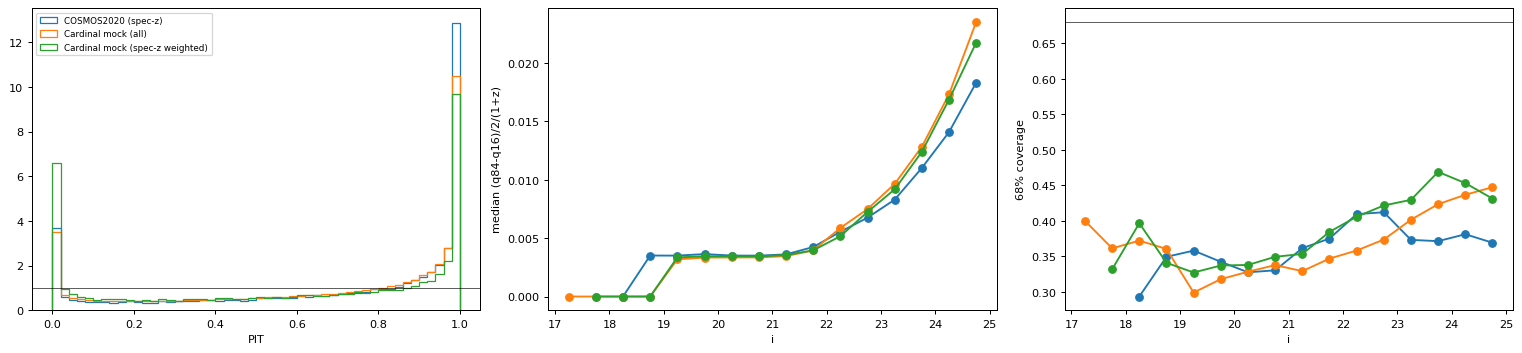

In [16]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4))
for name, (df, w) in {'data': (Ds, None), 'sim': (S, None), 'sim_w': (S, 'w_spec')}.items():
    axs[0].hist(df.PIT, bins=50, range=(0, 1), histtype='step', density=True, weights=None if w is None else df[w], color=COLORS[name], label=LABELS[name])
    t = binned(df, 'i_mag', np.arange(17, 25.01, 0.5), w)
    axs[1].plot(t.x, t.sig68, 'o-', color=COLORS[name]); axs[2].plot(t.x, t.cov68, 'o-', color=COLORS[name])
axs[0].axhline(1, c='k', lw=0.5); axs[0].set_xlabel('PIT'); axs[0].legend(fontsize=7)
axs[1].set_xlabel('i'); axs[1].set_ylabel('median (q84-q16)/2/(1+z)'); axs[2].set_xlabel('i'); axs[2].set_ylabel('68% coverage'); axs[2].axhline(0.68, c='k', lw=0.5)
plt.tight_layout(); plt.show()

## Key findings (run of 2026-11-10; 300k mock galaxies vs 33k COSMOS2020 spec-z galaxies, z<2.2, i<25)
1. **Pipeline check.** Our LePhare rerun reproduces the official COSMOS2020 photo-z: σ_NMAD 0.0119 vs 0.0107 and η 3.7% vs 3.6% against spec-z. Rerun vs official on all galaxies: σ_NMAD 0.007.
2. **Scatter vs magnitude matches.** At fixed i, the mock σ_NMAD follows the data closely: ≈0.010 / 0.015 / 0.020 / 0.031 in i = <22 / 22–23 / 23–24 / 24–25, vs 0.009 / 0.011 / 0.018 / 0.031 for the data.
3. **Catastrophic outliers are under-produced in the mock at faint magnitudes.** At 23–24 the outlier rate is 1.1% (mock) vs 6.4% (data); at 24–25 it is 4.1% vs 13.9%. In the data they concentrate at low true z (z<0.5) and in red i−Ks. The mock has no galaxies at z>2.3, has a less diverse SED library, and has perfectly Gaussian noise (apart from IRAC), all of which suppress outliers.
4. **Bias.** Overall the mock is biased more negative at faint mags (−0.012 at 24–25 vs −0.004). Its bias also depends on colour: it is positive for blue (g−i<0.5) and negative for red (g−i 1.5–2.5) galaxies, while in the bright brackets at 1.0<z<1.5 the data's bias is flatter for blue galaxies.
5. **Very blue mock galaxies (g−i<0.25) are a failure mode of the mock** (high η and σ at 0.5<z<1.5), which reflects the kcorrect SED library.
6. **Weighted to the spec-z selection,** the mock's global metrics (σ_NMAD 0.0125, η 3.9%) look like the data's (0.0119, 3.7%). The agreement is partly coincidental: the mock's extra blue-galaxy outliers stand in for the data's faint low-z outliers.
7. **PDFs are over-confident in both** (68% coverage ≈0.35–0.45). Part of this is the 0.01 redshift grid: bright objects' PDFs are narrower than one grid step, which produces the PIT spikes at 0 and 1.